# **Applied Data Analysis - Project Milestone P2**
## *How to be funny, for dummies.*

**<font size="4">Team: *JSON Derulo*</font>**<br>
- Adrián Fernández Lojo - adrian.fernandezlojo@epfl.ch
- Hanna Zwygart - hanna.zwygart@epfl.ch
- Jeremy Alexandre Serillon - jeremy.serillon@epfl.ch
- Mariem Maazoun - mariem.maazoun@epfl.ch
- Marina-Carmen Meredith Romero - marina.meredith@epfl.ch

Github repository: https://github.com/epfl-ada/ada-2025-project-json-derulo
<br><br><br>
_Note: Generative AI was used in this project to help us code some functions._
<br><br><br>

<!-- 
Make sure to read the [P2_README.md](P2_README.md) file.
<br><br>

**<font size="4">Table of Content</font>**

0. [Introduction](#0.-Introduction) <br>
0.1. [Abstract](#01-abstract) <br>
0.2. [Problematic](#02-problematic) <br>
0.3. [Dataset Description](#03-dataset-description) <br>
1. [General Data Visualizations](#1-general-data-visualizations) <br>
1.1. [Global Overview](#11-global-overview) <br>
1.2. [Overview of Contest Data](#12-overview-of-contest-data) <br>
1.3. [Intra Contest Overview](#13-intra-contest-overview) <br>
2. [Data pre-processing & cleaning](#2-data-pre-processing--cleaning) <br>
2.1. [Data Wrangling (filter, transform, ...)](#21-data-wrangling-filter-transform-) <br>
2.2. [Dataset Augmentation (enrich and adding new data)](#22-dataset-augmentation-enrich-and-adding-new-data) <br>
3. [Theme Analysis](#3-theme-analysis)
4. [Structural Analysis](#4-structural-analysis)
5. [Semantic Analysis](#5-semantic-analysis)
6. [Context Analysis](#6-context-analysis)
7. [Conclusion](#7-conclusion) -->

## 0. Introduction



### 0.1. Abstract

_"A day without laughter is a day wasted"_ - Charlie Chaplin

Each week, the NewYorker magazine provides an original cartoon, with a missing caption. Readers are thus invited to not only caption that week's contest, but also rate the previous week's image. 

In recent years, meme culture, and internet culture overall, has consistently prioritized shorter, and trending jokes. Tweets, TikToks, and even indirectly related formats, are tending to become shorter and have visual support. This is one of the many factors that could define how an image supported joke lands.

In this project, we have decided to dive into the NewYorker's caption contest dataset, which will give us great insights into humour, one of the most complex forms of human communication. We aim to discover the themes, structures, semantics, context and other subtleties that make something "funny".

<!-- Being funny is generally defined as a deeply cultural, societal and even contextual skill. When looking at our dataset, naturally, the following questions emerged : How can funniness be quantified ? Is humor objective ? 
Humour is a good reflection of society. The NYT caricatures are iconic, and captures years of societal, political and even government changes. We were therefore naturally drawn towards this dataset. We thought it would be interesting to see the evolutions of these captions over multiple years, through COVID etc…
The story we would like to tell is the story of what defines a funny or unfunny joke.
How do people react to the semantics and structure of a joke?  In our opinion, we would expect certain themes or joke structure to work better than others.  -->

### 0.2. Problematic

**Main problematics** <br>
How can we qualify and quantify jokes in terms of themes, structures and semantics (type of joke)?  <!-- and context (image desc. + temporal) -->

**Research questions and directions**<br>
Based on the objectives presented in the abstract, we aim to tackle the following concrete questions : 

1. Theme analysis:<br>
   1.a) What themes have a tendency to be ranked better ?<br>
   1.b) How theme relationships work between image and their text prompt (one way, or two-way) ?

2. Structural analysis: <br>
   2.a) Keep it short and simple: Are shorter jokes actually funnier ?<br>
   2.b) Are jokes with specific punctuation and rythms more effective ?

3. Semantic analysis:<br>
   3.a) What type of jokes over or underperform ? More specifically, which of the following categories perform best : dark humor, irony, social commentary, wordplay or absurdity ?

4. Timing analysis: <br>
   4.a) Is comedic timing actually that important ? 
<!-- 
1. Theme analysis: <br>
1.a. What themes have a tendency to be ranked better? We have found a LLM method which could help answer this question.<br>
1.b. How theme relationships work between image and their text prompt (one way, or two-way)?<br>

1. Structural analysis:<br>
2.a. Keep it short and simple : Are shorter jokes funnier? Are they more eﬀective by their ‘simplicity’?<br>
2.b. Are jokes with specific punctuation, rythme, … are effective?<br>

1. Semantic analysis:<br>
3.a. What type of jokes over or underperform? Types of joke: dark humor, irony, social commentary, wordplay, absurdity … [Deceptive Humor Dataset (DHD)](https://arxiv.org/abs/2503.16031)

1. Context influence, how do external factors influence Humor? (enrich dataset)<br>
4.a. Actuality (polytical, environmental, …) [GDELT](http://data.gdeltproject.org/events/index.html)<br>
4.b. Who is the targeted public, location, age? [Paper1](https://www.pewresearch.org/politics/2012/09/27/section-4-demographics-and-political-views-of-news-audiences/#:~:text=Regular%20readers%20of%20the%20New,talk%20programs%2C%20have%20older%20audiences.), [Paper2](https://www.library.illinois.edu/infosci/is-publications/civilian-publications/the-new-yorker/)<br>
4.c. [Dropped] Does an image's complexity visually play a role?<br>

1. [Dropped] How well can NLP perform in these types of contexts ? -->


### 0.3. Dataset description

The NewYorker's caption contest dataset follows the structure depicted below:
```bash
.
├── contests.json
├── data/
│   ├── 510.csv
│   ├── 511.csv
│   ...
│   ├── 894.csv
│   └── 895.csv
└── images/
    ├── 510.jpg
    ├── 511.jpg
    ...
    ├── 894.jpg
    └── 895.jpg
```

The ```contest.json``` holds the following data: _image path_, corresponding .csv _data path_ & _metadata_. The _metadata_ is a dictionary containing: the number of captions (present in the corresponding .csv file), image locations description (e.g. "streets", "a field", "wedding", ...), images descriptions ("A man walks outside."), image uncanny descriptions, related questions & related Wikipedia entities.

The corresponding contest image csv files, e.g. ```510.csv```, hold the following keys: <br>
funniness rank 'rank', 'caption', 'mean', 'precision', 'votes', 'not_funny', 'somewhat_funny' & 'funny'.


#### Scoring methods:

Linkert scale method:

|      Rating    |  Score |
| :-------------:| :----: |
| not funny      |  +1    |
| somewhat_funny |  +2    |
| funny          |  +3    |

The mean is the Arithmetic mean of all the scores for a specific caption $\sum_{i=1}^{n} score_i / n$ where $n$ is the number of votes <br>

The precision is the Standard Error of the Mean (SEM) $\sigma / \sqrt{n}$ where $\sigma$ is the standard deviation of the scores $\sigma^2=\frac{1}{n}\sum_{i=1}^{n}(mean-score_i)^2$. <br>



The dataframes are already sorted by the mean so we wont change the order <br>


### 0.4. Our Data Story

We developed our website, available at **[INSERT LINK]**, following the overall structure and narrative of this notebook. 
The website was designed with accessibility and user engagement in mind. Interactive components and progressive explanations allow readers to explore the data at their own pace, while maintaining a coherent narrative structure. We also tried to replicate the NewYorker-style witty and snarky editorial writing.


Several interactive elements were added to enrich the user experience:

0.4.1. Caption Analyzer

The *Caption Analyzer* is designed to assess how well readers have internalized the insights derived from the structural analysis (see Section 4.1). By actively engaging with the content, users can test their understanding of what makes a caption effective and humorous.

0.4.2. Ending Quiz

For the final quiz, we carefully selected the cartoons on which users are tested. This selection was based on the function `print_top3_biggest_deltas`, which relies on the `computing_deltas` method. The latter computes, for each contest, the score margin (delta) between the two highest-rated captions, using their mean funniness scores extracted from the cleaned CSV files. This margin serves as a quantitative measure of how decisively the top caption outperformed the runner-up.

We considered contests with larger deltas to be particularly relevant, as they correspond to cartoons with a more clearly identifiable “objectively funniest” caption. Using this criterion, we selected **contest 600, contest 690, and contest 555**.

0.4.3. Visualizations

Finally, we chose to incorporate external tools such as **Flourish** and **Plotly** in order to produce visually engaging and accessible interactive visualizations, enhancing both clarity and aesthetic appeal. We have also established a plotly theme, of colors and typos, to make the reader-experience as immersive and coherent as possible.


By combining statistical analysis with interactive elements, our datastory aims not only to present results, but also to encourage users to actively reflect on what makes a caption successful.



In [ ]:
#print_top3_biggest_deltas(CSV_CLEAN_DIR)

NameError: name 'print_top3_biggest_deltas' is not defined

## 1. General Data Visualizations

In [16]:
# General
import os
from pathlib import Path

# data manipulation
import json
import pandas as pd
import numpy as np

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt
#for theme
%run ../../docs/plotly_theme.ipynb 
# from matplotlib import cm

# Interactive Jupyter
from IPython.display import display

# others
import contractions
from scipy.stats import pearsonr, ttest_ind, f_oneway
import nltk
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
nltk.download('stopwords')

# Custom utility python files
#import Utils.visualization as viz # custom visualization utils in '/utils/visualization.py'
#import Utils.joke_classification as jc # custom joke classification utils in '/utils/joke_classification.py'
# import utils.data_augmentation as da # custom data augmentation utils in '/utils/data_augmentations.py'
import Utils.utils_structural_analysis as ut

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mered\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [5]:
# PATH PROJECT SETUP
PROJECT_ROOT = Path.cwd().parent.parent
FIGURES_DIR = PROJECT_ROOT / 'figures'

# DATA DIRECTORIES
DATA_DIR = PROJECT_ROOT / 'data' / 'newyorker_caption_contest'
JSON_DIR = DATA_DIR / 'contests.json'
CSV_DIR = DATA_DIR / 'data'
CSV_CLEAN_DIR = DATA_DIR / 'data_cleaned'
IMG_DIR = DATA_DIR / 'images'
CLASS_DIR=DATA_DIR / 'LLM_classifications'

print("Project path setup:")
print("PROJECT_ROOT:  ", PROJECT_ROOT)
print("FIGURES_DIR:   ", FIGURES_DIR)
print("\nDATA_DIR:      ", DATA_DIR)
print("JSON_DIR:      ", JSON_DIR)
print("CSV_DIR:       ", CSV_DIR)
print("CSV_CLEAN_DIR: ", CSV_CLEAN_DIR)
print("IMG_DIR:       ", IMG_DIR)
print("CLASS_DIR:     ", CLASS_DIR)

Project path setup:
PROJECT_ROOT:   c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo
FIGURES_DIR:    c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\figures

DATA_DIR:       c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest
JSON_DIR:       c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\contests.json
CSV_DIR:        c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data
CSV_CLEAN_DIR:  c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data_cleaned
IMG_DIR:        c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\images
CLASS_DIR:      c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_ca

### 1.1. Global Overview

Let us take a look at our raw dataset. Feel free to play with the slider to visualize different contest images and corresponding metadatas (if any).

In [3]:
# Load the JSON file => pandas DataFrame
file_path = str(JSON_DIR)
with open(file_path, "r") as file:
    contests = json.load(file)
contests_df = pd.DataFrame(contests)

# Visualize the contests with interactive viewer
viewer = viz.make_contest_viewer(contests_df, file_path)
display(viewer)

Once you have selected a contest ID with the slider, run the next cell to visualize some plots of the corresponding .CSV file.

Current selected 'contest_id' = 510


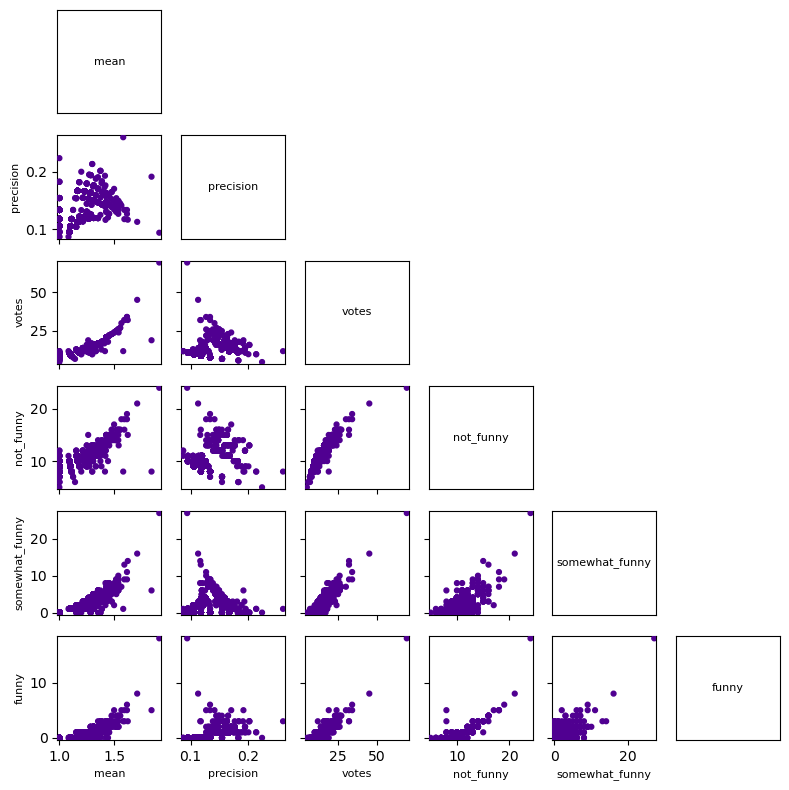

In [4]:
contest_id = int(viewer.slider.value)
print("Current selected 'contest_id' =", contest_id)

# Load corresponding CSV file
contest_row = contests_df[contests_df["contest_id"] == contest_id]
if not contest_row.empty:
    csv_rel_path = contest_row.iloc[0]["data"]
    csv_path = os.path.join(os.path.dirname(file_path), csv_rel_path)
    if os.path.exists(csv_path):
        df_current = pd.read_csv(csv_path)
        viz.plot_df_pairgrid(df_current, cols=["mean","precision","votes", "not_funny",
                                               "somewhat_funny", "funny"],
                             trace="none", figsize=(8,8),
                             include_upper=False, diagonal="name")
    else:
        print(f"CSV file not found at {csv_path}")
else:
    print(f"No contest found for contest_id {contest_id}")

In [5]:
print(contests_df.count())

contest_id    384
image         384
data          384
metadata      240
dtype: int64


votes distribution

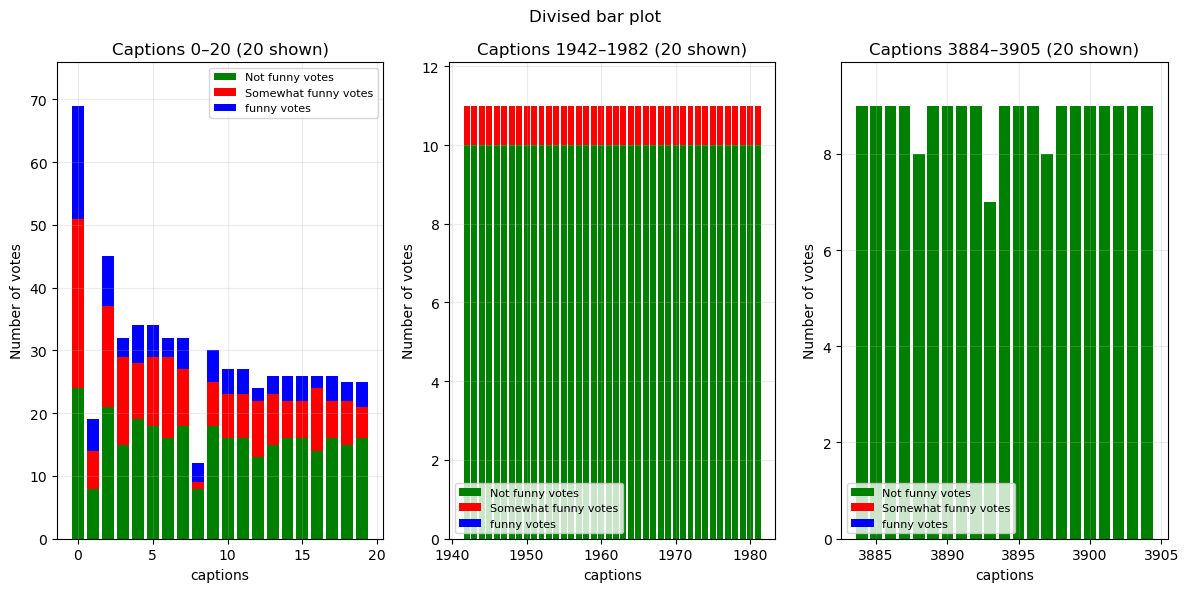

In [6]:
filename = f"{contest_id}.csv"
file_path = os.path.join(CSV_DIR, filename)
df=pd.read_csv(file_path)
viz2.plot_divised_histo_stacked(pd.read_csv(file_path))

means distribution :

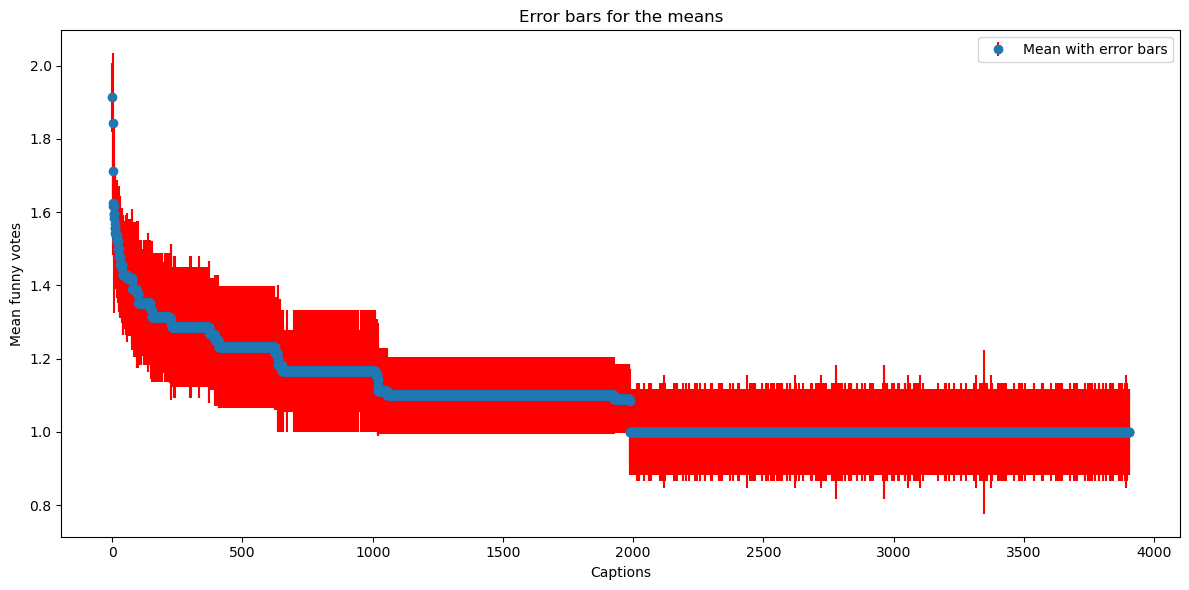

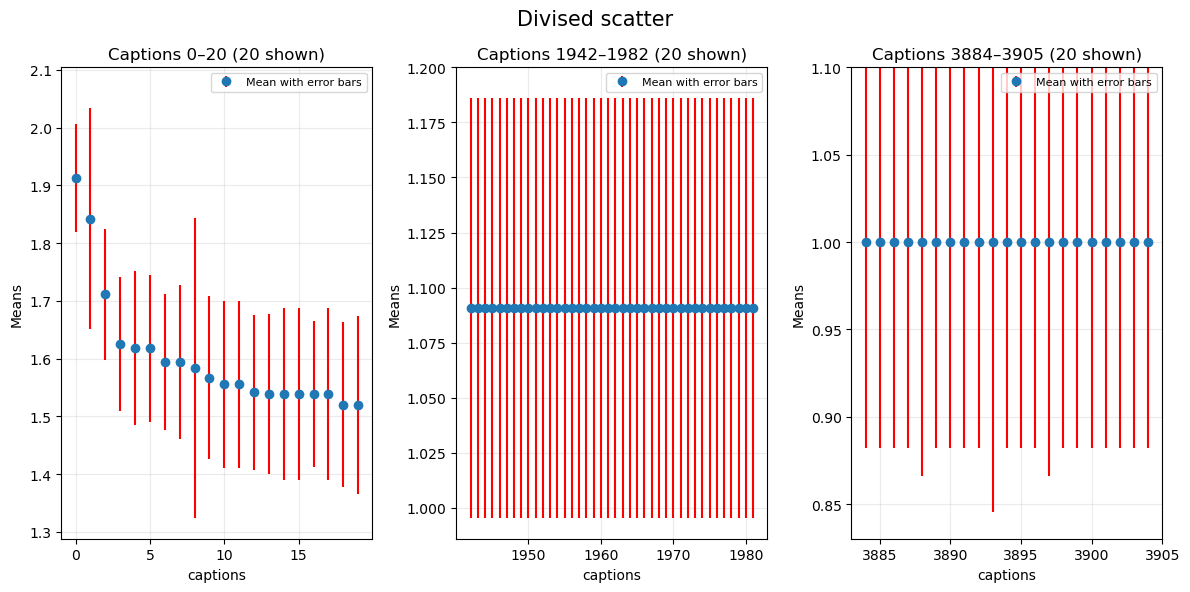

In [7]:
viz2.scatter_error(df)
viz2.plot_divised_scatter_error(df)

It looks like a heavy-tailed distribution!

Some data exploration : <br>
<br>
-Top1 Means vs all context

File not found: 525.csv
File not found: 540.csv

Top 5 contests by mean of top 1 captions:
     Contest  Top1_Mean
88       600   2.998918
178      690   2.671296
43       555   2.634196
153      665   2.518294
7        517   2.391304

Bottom 5 contests by mean of top 1 captions:
     Contest  Top1_Mean
128      640   1.633028
383      895   1.632287
132      644   1.600000
125      637   1.576744
131      643   1.552036

Highest mean contest: #600.0 with mean score 2.999
Lowest mean contest: #643.0 with mean score 1.552


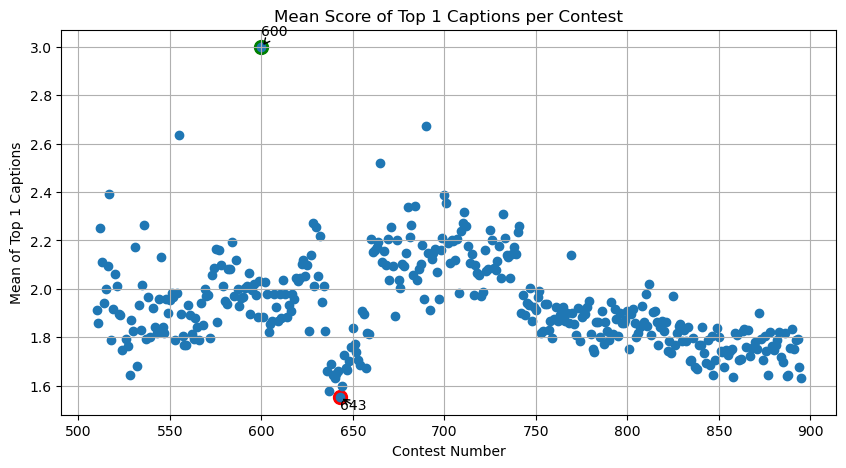

Contest with the best mean score on top 1 captions : 


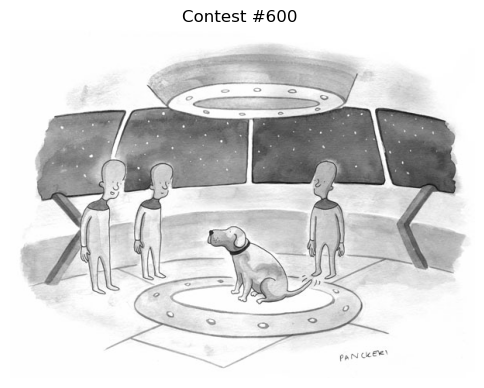


Contest 600 Top Caption:
Rank 1: 'Mission accomplished. We will report that this planet's inhabitants are friendly and playful.' with mean score 2.999
Contest with the worst mean score on top 1 captions : 


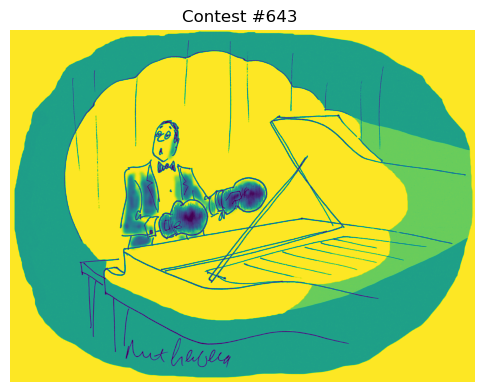


Contest 643 Top Caption:
Rank 1: 'My next selection sounds just like the last one.' with mean score 1.552


In [8]:
viz2.top1_means_vs_contests(CSV_DIR,IMG_DIR)

-Number of caption vs contests

File not found: 525.csv
File not found: 540.csv

Top 5 most popular contests:
     Contest  Num_Captions
204      716         15329
232      744         12354
228      740         11108
241      753         11069
195      707         10718

Top 5 least popular contests:
     Contest  Num_Captions
124      636          2930
86       598          2919
324      836          2032
322      834          1444
323      835          1066

Most popular contest: #716 with 15329 captions.
Least popular contest: #835 with 1066 captions.


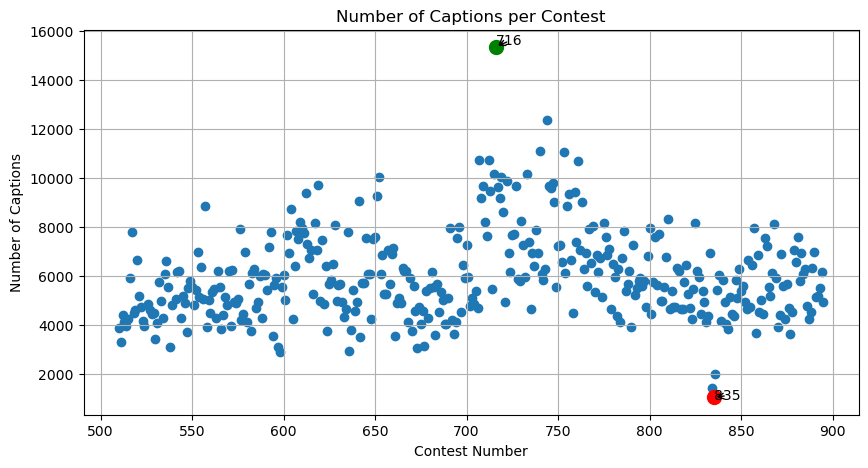

In [9]:
viz2.plot_number_of_captions_vs_contests(CSV_DIR,IMG_DIR)

it seems that contest 716 might be an outlier <br>
<br>

- Funy captions distribution

In [10]:
viz2.plot_funny_dist(CSV_DIR)

,contest_id,funny
1,510,519
2,511,460
3,512,476
4,513,545
5,514,2350
...,...,...
380,891,4355
381,892,4584
382,893,5031
383,894,5076


We should perhaps look more into contest 744. <br>

### 1.2. Overview of Contest Data (```contests.json``` file)

- missing metadatas (dictionaries): 144
- 2 missing contest: 525 & 540

In [11]:
# check missing contest (in the interval 510-895)
missing_contest = []
missing_csv = []
for id in range(510, 896):
    # missing contest id in json file
    if id not in contests_df['contest_id'].values:
        missing_contest.append(id)
    # missing csv file in DATA_DIR
    csv_path = CSV_DIR / f"{id}.csv"
    if not csv_path.exists():
        missing_csv.append(id)
        
print("Missing contest IDs in json file:", missing_contest)
print("Contests with missing CSV files in DATA_DIR:", missing_csv)

Missing contest IDs in json file: [525, 540]
Contests with missing CSV files in DATA_DIR: [525, 540]


In [12]:
# check missing metadata for each (present) contest id
missing_metadata = contests_df[contests_df['metadata'].isnull()]
print(f"Count of missing metadata: {len(missing_metadata)}")
print("Contest IDs with missing metadata:", missing_metadata['contest_id'].tolist())

Count of missing metadata: 144
Contest IDs with missing metadata: [527, 564, 588, 597, 605, 615, 644, 647, 656, 657, 670, 714, 764, 765, 766, 767, 768, 769, 770, 771, 772, 773, 774, 775, 776, 777, 778, 779, 780, 781, 782, 783, 784, 785, 786, 787, 788, 789, 790, 791, 792, 793, 794, 795, 796, 797, 798, 799, 800, 801, 802, 803, 804, 805, 806, 807, 808, 809, 810, 811, 812, 813, 814, 815, 816, 817, 818, 819, 820, 821, 822, 823, 824, 825, 826, 827, 828, 829, 830, 831, 832, 833, 834, 835, 836, 837, 838, 839, 840, 841, 842, 843, 844, 845, 846, 847, 848, 849, 850, 851, 852, 853, 854, 855, 856, 857, 858, 859, 860, 861, 862, 863, 864, 865, 866, 867, 868, 869, 870, 871, 872, 873, 874, 875, 876, 877, 878, 879, 880, 881, 882, 883, 884, 885, 886, 887, 888, 889, 890, 891, 892, 893, 894, 895]


### 1.3. Intra Contest Overview (.csv files)

- corrupted rows: in all ... we have 64'007 corrupted rows in all of the .csv files for a total of 2'292'677 rows. Here is an example below of corrupted rows in file ```523.csv```, row n°492 to n°506. As we can not make an assumption of which number is exploitable, we decided to exclude those lines. For more details, please refer to section [2.1 Data Wrangling](#21-data-wrangling-filter-transform-).  <br><br>
    <img src="../../figures/documentation/corrupted-csv.png" width="600"/>
<br><br>
- missing 'rank' columns in some .csv file such as ```663.csv```. Although the 'rank' column was missing, the order of the .csv was preserved so we added it.


## 2. Data pre-processing & cleaning

Let's explore more in depth the data and clean it

### 2.1. Data Wrangling (filter, transform, ...)

All of the data filtering functions are available in data_filtering.py.
The first thing we have looked into is fixing our header on all our files. 

The expected headers are the following : 
| Header |
|-----------|
|rank|
|caption|
|mean|
|precision|
|votes|
|not_funny|
|somewhat_funny|
|funny|



Indeed, we have noticed that, in our total 300+ contest files, they did not have matching headers. The "rank" header was often missing.

In order to fix that, we have started by first checking which contest did not have the excpected headers, then fixing them. Details on this can be consulted in the [data_filtering.py](../../src/Milestone_P2/utils/data_filtering.py).
| Function | Description |
|-----------|-----------|
| has_correct_headers| prints an error message when the CSV file does not have the right headers  |
| fix_missing_rank | adds a rank column based on decreasing mean values.|

Secondly, we started to look deeper into our individual lines. Namely, we have found that some lines in our CSV files were not formatted corresponding to our 8 header categories.

The objective was to delete those data lines, as they are not exploitable in order to yield reliable results. To do so, we have coded 3 functions which help us detect, and eventually aim at deleting the corrupted lines. These functions are the following : 

| Function | Description |
|-----------|--------------|
| check_corruption| Returns a list of reasons if the line is corrupted, based on our pre-defined criterias|
| check_csv_file_for_corruption| Returns a list of row indices that are corrupted in a given CSV file as well as some other metrics|
| clean_csv_using_corruption|  Cleans a CSV file by removing corrupted rows found by check_csv_file_for_corruption as well as saves the cleaned file in a 'data_cleaned' folder in the same parent directory.|

The aim was to create a new folder called *data_cleaned*, which contains all our CSV files in their final, filtered form. However, we still need to tweak the clean_csv_using_corruption() function, before having the desired results.  Once again, details on the above-mentioned functions can be found in the following file : [data_filtering.py](../../src/Milestone_P2/utils/data_filtering.py).

First of all, we want to do a sanity check on our data to check if there are no errors in our data. To do so, we wrote the ```check_votes ()``` function from the file [data_wrangling.py](../../src/Milestone_P2/utils/data_wrangling.py). that checks if the num_votes in the json file actually corresponds to the sum of the votes in the csv files. We also manually checked if the number of rows in the csv files also correspond to the num_captions in the json.

We also noticed 2 missing contests: ```525``` and ```540```. 
=> reasons: filter data captions that are sensitive or sensitive context.
To counter that, we wrote 

### 2.2. Dataset Augmentation (enrich and adding new data)

We noticed that contest Metadata is missing from the json file in 144 contests like in contest 527 or contest 564 like shown above in 1.2 part. To rectify that, we buit the ```update_metadata_from_csv``` function from the file [data_wrangling.py](../../src/Milestone_P2/utils/data_wrangling.py) that adds the missing num_captions and num_votes to the metadata dictionary

In [13]:
df_contest_updated= dw.update_metadata_from_csv(contests_df,CSV_DIR)


We can then do the sanity check of votes on the given and added num_votes. This function compute the number of votes from the .csv and compares that number from the one given in the ```contests.json```  metadata. That way we can control if everything is in order.

In [14]:
dw.check_votes(df_contest_updated, CSV_DIR)

Total contests checked: 384
Matching vote counts: 384
Mismatches or missing: 0


,contest_id,csv_found,csv_votes,json_votes,match
0,510,True,41185,41185,True
1,511,True,28205,28205,True
2,512,True,21574,21574,True
3,513,True,16894,16894,True
4,514,True,95790,95790,True
...,...,...,...,...,...
379,891,True,928856,928856,True
380,892,True,788251,788251,True
381,893,True,1085745,1085745,True
382,894,True,878676,878676,True


We also added the dates corresponding to all the contests following the date of the first contest 510 (22 Feb 2016). To rectify that, we buit the ```add_contest_dates()``` function from the file [data_wrangling.py](../../src/Milestone_P2/utils/data_wrangling.py)

In [15]:
df_contest_dates= dw.add_contest_dates(df_contest_updated)
df_contest_dates.head()


,contest_id,image,data,metadata
0,510,images/510.jpg,data/510.csv,"{'num_captions': 3905, 'num_votes': 41185, 'im..."
1,511,images/511.jpg,data/511.csv,"{'num_captions': 3325, 'num_votes': 28205, 'im..."
2,512,images/512.jpg,data/512.csv,"{'num_captions': 4399, 'num_votes': 21574, 'im..."
3,513,images/513.jpg,data/513.csv,"{'num_captions': 4141, 'num_votes': 16894, 'im..."
4,514,images/514.jpg,data/514.csv,"{'num_captions': 3951, 'num_votes': 95790, 'im..."


We also want to add the missing images descriptions with the ```add_image_descriptions()``` function refer to [data_augmentation.py](), eventhough it does not work yet.

## 3. Theme Analysis / What theme is the funniest ?

### 3.1. Proposed Pipeline

Here are the main tools and techniques that will be used in the theme extraction pipeline:
   - Pre-process to keep only meaningful words ("This is politic." => "politic")
   - Sentence Embeddings (BERT / Sentence-BERT / CLIP text encoder) - converts text => semantic vector representation.
   - Spherical k-means - clusters embeddings to form our themes.
   - c-TF-IDF (**c**lass-based **T**erm **F**requency-**I**nverse **D**ocument **F**requency) - extracts and labels the most representative words for each cluster/theme.
   - (previously tested) BERTopic - topics clustering approach that inspired the pipeline but is less scalable and less controllable for large datasets such as ours.

We will extract our themes from our decscriptions/captions like so:
   - images descriptions processed all at once to allow clustering them to each other independantly from the captions.
   - captions processed for each contest internally: extract the themes of all the caption for all specific contest once at a time.
   
This allows us to analyse and discuss behaviours inside each contest and also to parts the computation. To do more general analysis across ALL the captions, we will then do additional clustering to group back all the intermidiate, contest-wise, results.

To assess whether image and caption themes are statistically associated, we will construct a contingency table of their co-occurrences and apply chi-square test or pointwise mutual information (PMI/NPMI) to identify theme pairs that occur significantly more or less often.

### 3.2. Tested method - proof of concept

We have done a proof of concept test file that you can found here at: [BERTopic_test.py](/src/Milestone_P2/utils/BERTopic_test.py). To synthesise, we use some text samples to test BERTopic.

Here is the input:
```python
    texts = ["This is a political caption.",                            # Test captions
            "This is a funny caption.",                                 #  |
            "This is a caption about animals.",                         #  V
            "This is a caption about technology.",
            "This is a caption about sports.",
            "This is a caption about food.",
            "This is a caption about travel.",
            "This is a caption about health.",
            "This is a caption about education.",
            "This is a caption about environment.",             
            "When the right woman comes along, I'll know it.",          # Captions from the dataset
            "Anyone who steps on me is out!",                           #  |
            "Guess I should have jumped from a few floors higher.",     #  V
            "Does this suit make me look flat?",
            "I used to lie in the gutter, but then I quit drinking.",
            "If you can meditate here, you can meditate anywhere."]
```
<br><br>
And here the results obtained with BERTopic by running the [BERTopic_test.py](/src/Milestone_P2/utils/BERTopic_test.py) file:
```bash
    2025-10-25 02:10:57,242 - BERTopic - Embedding - Transforming documents to embeddings.
    Batches: 100%|████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.23it/s]
    2025-10-25 02:10:58,076 - BERTopic - Embedding - Completed ✓
    2025-10-25 02:10:58,076 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
    OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
    2025-10-25 02:11:00,470 - BERTopic - Dimensionality - Completed ✓
    2025-10-25 02:11:00,470 - BERTopic - Cluster - Start clusterixng the reduced embeddings
    2025-10-25 02:11:00,471 - BERTopic - Cluster - Completed ✓
    2025-10-25 02:11:00,472 - BERTopic - Representation - Fine-tuning topics using representation models.
    2025-10-25 02:11:01,007 - BERTopic - Representation - Completed ✓

       Topic                                    Name  Count
    0     -1  -1_caption_animals_education_political      5
    1      0            0_caption_health_food_sports      3
    2      1            1_caption_technology_this_is      2
```


We can see that we obtain 3 clusters of themes with the corresponding instances count. We keep in mind that the more caption/text samples we will input to BERTopic => the most reliable the topics clustering results will be. As explained above, we started by using BERTopic inspired the pipeline but is less scalable and less controllable for large datasets such as ours. This is why we will use and study the option explained above in the futur.

## 4.Structural Analysis / What structure of joke is the funniest ?

### 1. Load the data set and make the captions more fluid

Load the data set: 

In [7]:
# load the data set 
path = "C:/Users/mered/OneDrive/Escritorio/Marina/MA2/ADA/ada-2025-project-json-derulo/data/newyorker_caption_contest/newyorker_caption_contest/THEMES_RESULTS_V4/docs_with_themes.csv"

df_og = ut.load_docs_with_theme_csv(path)
df = df_og.loc[df_og['kind'] != 'image']

df.head(5)

,doc_id,contest_id,kind,text,clean_text,rank,mean,precision,votes,not_funny,somewhat_funny,funny,theme_id,theme_label
1,caption_510_0,510,caption,I'm a congressman--obstruction is my job.,congressman obstruction job,0.0,1.913043,0.094022,69.0,24.0,27.0,18.0,64,Election
2,caption_510_1,510,caption,"I'm what they mean when they say, 'The middle ...",mean middle class step,1.0,1.842105,0.191381,19.0,8.0,6.0,5.0,53,Market
3,caption_510_2,510,caption,Does this suit make me look flat?,suit look flat,2.0,1.711111,0.112915,45.0,21.0,16.0,8.0,76,Clothing
4,caption_510_3,510,caption,"When the right woman comes along, I'll know it.",right woman come know,3.0,1.625000,0.116657,32.0,15.0,14.0,3.0,45,Marriage
5,caption_510_4,510,caption,"I used to lie in the gutter, but then I quit d...",lie gutter quit drinking,4.0,1.617647,0.133610,34.0,19.0,9.0,6.0,79,Beer


Make the captions more fluid by: 
- erasing unnecessary punctuations 
- lowercase all the captions 
- handling contractions to normalise all the captions 
        -> necessary for comparison 

In [9]:
# check for missing values and fill NaN w/ empty string or remove them
print(f"missing values in caption: {df['text'].isna().sum()}")
df["text"] = df["text"].fillna("")

# erase unnecessary punctuations :
df["text"] = df["text"].str.replace(r"[--]", " ", regex=True)
df["text"] = df["text"].str.replace(r"[.,?]", " ", regex=True)

# lowercase : 
df["text"] = df["text"].str.lower()

# contractions :
df["text"] = df["text"].apply(lambda x: contractions.fix(x))   

print(df["text"].head()) # check

missing values in caption: 52


C:\Users\mered\AppData\Local\Temp\ipykernel_2752\476613438.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["text"] = df["text"].fillna("")
C:\Users\mered\AppData\Local\Temp\ipykernel_2752\476613438.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["text"] = df["text"].str.replace(r"[--]", " ", regex=True)
C:\Users\mered\AppData\Local\Temp\ipykernel_2752\476613438.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_index

1           i am a congressman  obstruction is my job 
2    i am what they mean when they say  'the middle...
3                    does this suit make me look flat 
4    when the right woman comes along  i will know it 
5    i used to lie in the gutter  but then i quit d...
Name: text, dtype: object


C:\Users\mered\AppData\Local\Temp\ipykernel_2752\476613438.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["text"] = df["text"].apply(lambda x: contractions.fix(x))


### 4.2 Are longer jokes funnier than shorter ones? What about jokes with more complex vocabulary?

The average of words and characters of the entire data set: 

In [11]:
# words
df["word_counts"] = [len(line.split()) for line in df["text"]]

# characters 
df["length"] = [len(line) for line in df["text"]]

# average of words and characters
print(f"Average word count: {df['word_counts'].mean():.2f}")
print(f"Average character count: {df['length'].mean():.2f}")
print(f"Data set size: {len(df)} captions")

C:\Users\mered\AppData\Local\Temp\ipykernel_2752\301036676.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["word_counts"] = [len(line.split()) for line in df["text"]]


Average word count: 10.56
Average character count: 53.43
Data set size: 2263088 captions


C:\Users\mered\AppData\Local\Temp\ipykernel_2752\301036676.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["length"] = [len(line) for line in df["text"]]


#### 4.2.1 Does the amount of words used in the caption influence the funniness score in general?

**Use of Pearsonr for the correlation analysis and ttest:**

C:\Users\mered\AppData\Local\Temp\ipykernel_2752\3972424741.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['total_votes'] = df['not_funny'] + df['somewhat_funny'] + df['funny'] # this is for each caption
C:\Users\mered\AppData\Local\Temp\ipykernel_2752\3972424741.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['total_votes'] = df['total_votes'].replace(0,1)
C:\Users\mered\AppData\Local\Temp\ipykernel_2752\3972424741.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a sl


correlation w/ funny Score:
# of words correlation: -0.038 (p-value: 0.000)
# of characters correlation: -0.043 (p-value: 0.000)


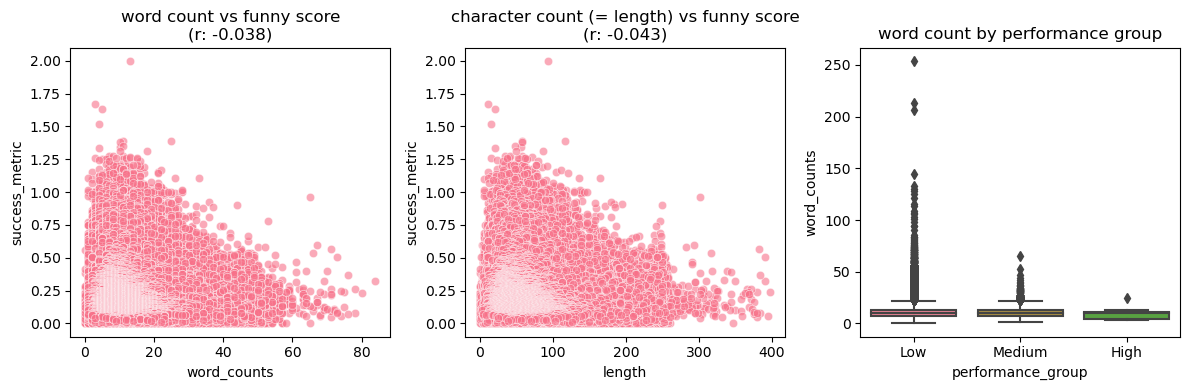

In [12]:
# style of plot
plt.style.use('default')
sns.set_palette("husl")

# scores
df['total_votes'] = df['not_funny'] + df['somewhat_funny'] + df['funny'] # this is for each caption 

# replace 0 tot_votes with 1 to avoid division by 0 
df['total_votes'] = df['total_votes'].replace(0,1)

# proportions for each category
df['prop_not_funny'] = df['not_funny'] / df['total_votes']
df['prop_somewhat_funny'] = df['somewhat_funny'] / df['total_votes']
df['prop_funny'] = df['funny'] / df['total_votes']

# weighted average (2 for funny, 1 for somewhat_funny, 0 for not_funny)
df['funny_score_weighted'] = (df['funny'] * 2 + df['somewhat_funny'] * 1 + df['not_funny'] * 0) / df['total_votes']
df['success_metric'] = df['funny_score_weighted']
df['success_metric'].replace([np.inf, -np.inf], np.nan, inplace=True)

df = df.dropna(subset=['word_counts', 'length', 'success_metric'])

# correlation analysis 
corr_word_score, p_word = pearsonr(df['word_counts'], df['success_metric'])
corr_char_score, p_char = pearsonr(df['length'], df['success_metric'])

print(f"\ncorrelation w/ funny Score:")
print(f"# of words correlation: {corr_word_score:.3f} (p-value: {p_word:.3f})")
print(f"# of characters correlation: {corr_char_score:.3f} (p-value: {p_char:.3f})")

df_filtered = df[(df['word_counts'] <= 100) & (df['length'] <= 400)]

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.scatterplot(data=df_filtered, x='word_counts', y='success_metric', alpha=0.6)
plt.title(f'word count vs funny score\n(r: {corr_word_score:.3f})')

plt.subplot(1, 3, 2)
sns.scatterplot(data=df_filtered, x='length', y='success_metric', alpha=0.6)
plt.title(f'character count (= length) vs funny score\n(r: {corr_char_score:.3f})')

plt.subplot(1, 3, 3)
# Create performance groups for comparison
df['performance_group'] = pd.cut(df['success_metric'], bins=3, labels=['Low', 'Medium', 'High'])

sns.boxplot(data=df, x='performance_group', y='word_counts')
plt.title('word count by performance group')

plt.tight_layout()
plt.show()



In [14]:
# statistical test for performance comparison & word count performance 

top_cutoff = df['success_metric'].quantile(0.8)
bottom_cutoff = df['success_metric'].quantile(0.2)

top_captions = df[df['success_metric'] >= top_cutoff]
bottom_captions = df[df['success_metric'] <= bottom_cutoff]

print(f"\nperformance comparison:")
print(f"top 20% cutoff: {top_cutoff:.3f} ({len(top_captions)} captions)")
print(f"bottom 20% cutoff: {bottom_cutoff:.3f} ({len(bottom_captions)} captions)")

# Compare metrics
print(f"\nword count comparison:")
print(f"top performers: {top_captions['word_counts'].mean():.1f} ± {top_captions['word_counts'].std():.1f}")
print(f"bottom performers: {bottom_captions['word_counts'].mean():.1f} ± {bottom_captions['word_counts'].std():.1f}")

print(f"\nlength count comparison:")
print(f"top performers: {top_captions['length'].mean():.1f} ± {top_captions['length'].std():.1f}")
print(f"bottom performers: {bottom_captions['length'].mean():.1f} ± {bottom_captions['length'].std():.1f}")

# Statistical test
t_stat, p_val = ttest_ind(top_captions['word_counts'], bottom_captions['word_counts'])
print(f"t-test p-value words: {p_val:.4f}")

t_stat, p_val = ttest_ind(top_captions['length'], bottom_captions['length'])
print(f"t-test p-value characters: {p_val:.4f}")


performance comparison:
top 20% cutoff: 0.298 (453068 captions)
bottom 20% cutoff: 0.118 (456784 captions)

word count comparison:
top performers: 10.3 ± 4.6
bottom performers: 10.9 ± 5.7

length count comparison:
top performers: 51.9 ± 23.3
bottom performers: 55.5 ± 29.1
t-test p-value words: 0.0000
t-test p-value characters: 0.0000


*Interpretation:*

| **Metric** | **Top 20%** | **Bottom 20%** |
|-----------|-----------|--------------|
| Mean word count | 10.3 | 11.0 |
| Standard deviation (word) | 4.6 | 5.8 |
| Mean character count | 52.1 | 56.0 |
| Standard deviation (characters) | 23.5 | 29.9 |

In both counting cases (words and characters) the t-test p-value is < 0.0001, which means that the the difference in count between the two types of performers is statistically significant, in other words, the probability that this difference happened by random chance is less than 0.0001%. 

Therefore, knowing this, we can say that the top performing captions tend to be shorter in words and characters than the bottom performing ones.This conclusion is interesting, and context is necessary: it looks like the practical difference is small but because we are working with a huge amount of captions, this difference is statistically significant.  

These observations can be done also through plot visualisation, where we can see that the captions that clearly have better scores are those that are shorter.

**Using other techniques to confirm the results**

ANOVA: 
- Until now, our boxplots used 3 groups based on performance => What about 10 equal-size length groups? 
- What this technique adds: more granular understanding => Maybe only extremely short/long jokes perform badly 



 One-way ANOVA results:
- F-statistic: 696.37
- p-value: 0.0000
- Significant differences exist between bins

Tukey HSD Post-hoc Test:
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     1     10  -0.0146    0.0 -0.0158 -0.0134   True
     1      2   0.0069    0.0  0.0059  0.0079   True
     1      3    0.008    0.0  0.0069  0.0091   True
     1      4   0.0076    0.0  0.0065  0.0087   True
     1      5   0.0083    0.0  0.0072  0.0095   True
     1      6   0.0086    0.0  0.0074  0.0097   True
     1      7   0.0081    0.0  0.0069  0.0094   True
     1      8   0.0055    0.0  0.0043  0.0066   True
     1      9   0.0002 0.9999 -0.0009  0.0014  False
    10      2   0.0215    0.0  0.0205  0.0226   True
    10      3   0.0226    0.0  0.0214  0.0238   True
    10      4   0.0222    0.0   0.021  0.0234   True
    10      5   0.0229    0.0  0.0217  0.0241   True
    10      6   

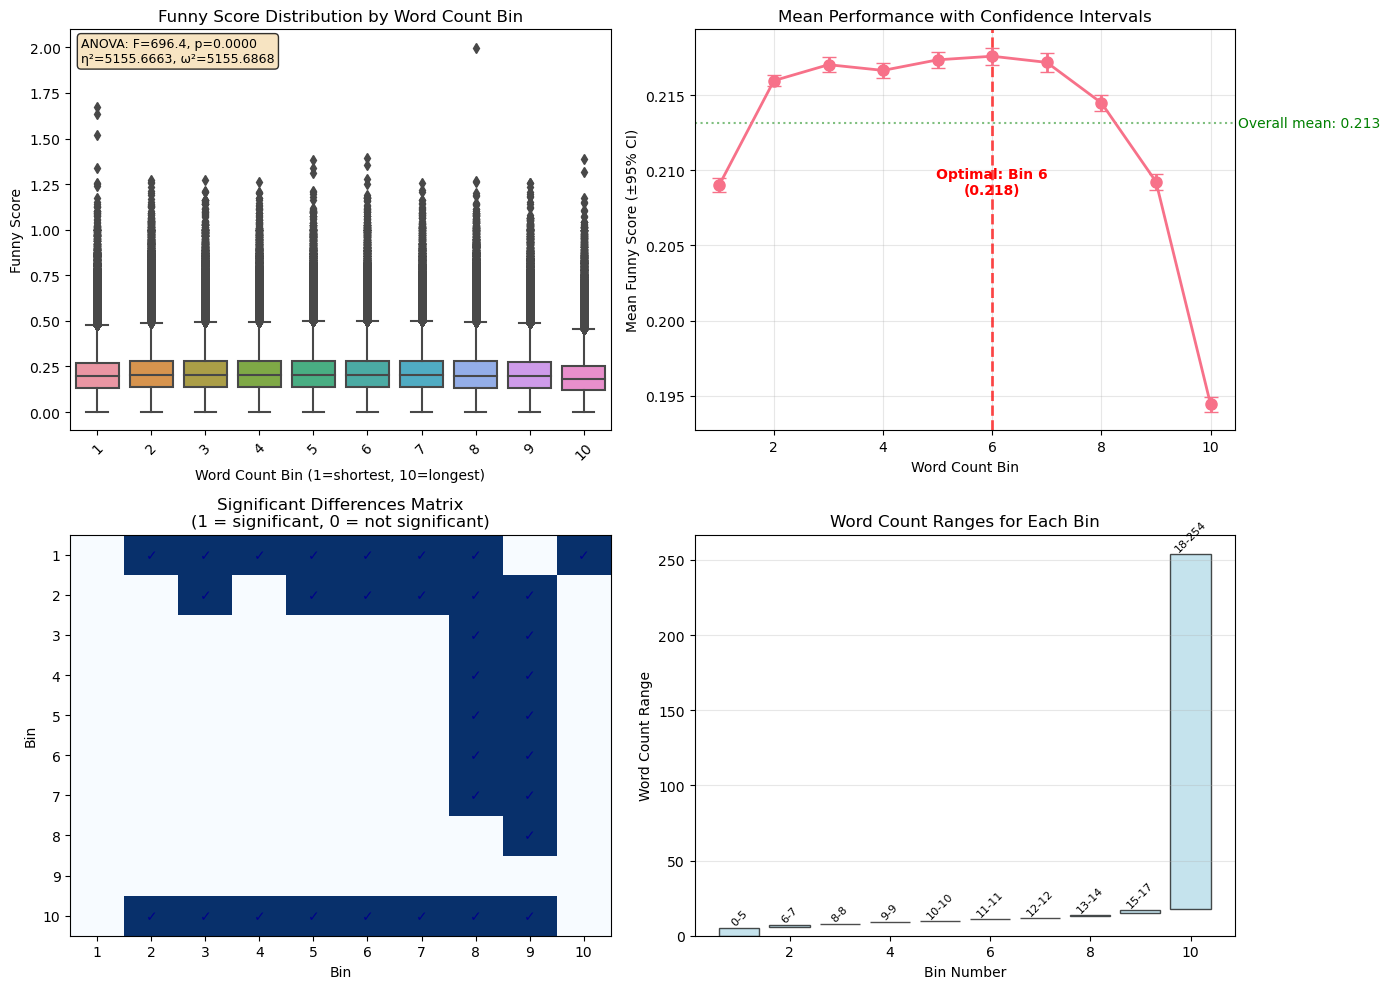


8. Linear trend across bins:
   - Slope: -0.000996 (change in score per bin)
   - Correlation: -0.0239
   - p-value for trend: 0.0000

9. Variance decomposition:
   - Total variance: 0.015008
   - Within-bin variance: 0.015000 (100.0%)
   - Between-bin variance: 0.000007 (0.0%)

10. ANOVA assumptions check:
   - Levene's test for equal variances: p = 0.0000
     Consider Welch's ANOVA instead
   • Shapiro-Wilk normality test: p = 0.0000
     Consider non-parametric alternative (Kruskal-Wallis)
   • Kruskal-Wallis non-parametric test: p = 0.0000

CONCLUSION FOR BINNING ANALYSIS

Based on the ANOVA with 10 bins:

1. STATISTICAL SIGNIFICANCE: YES
   - p-value = 0.0000
   - F-statistic = 696.37

2. EFFECT SIZE: Large
   - η² = 5155.6663
   - ω² = 5155.6868
   - Between-bin variance: 0.0% of total

3. PRACTICAL SIGNIFICANCE:
   - Optimal bin: 6 (word range: 11-11)
   - Score difference (best vs worst bin): 0.0232 points

4. ASSUMPTIONS:
   - Equal variances: VIOLATED
   - Normality: VIOLAT

In [17]:
# 10 equal-sized bins based on word count
df['word_bins'] = pd.qcut(df['word_counts'], q=10, labels=range(1, 11))

# statistics for each bin
bin_stats = df.groupby('word_bins').agg({'word_counts': ['min', 'max', 'mean'],'success_metric': ['mean', 'std', 'count']}).round(2)

# One-way ANOVA
groups = [group['success_metric'].values for _, group in df.groupby('word_bins')]
anova_result = f_oneway(*groups)

print(f"\n One-way ANOVA results:")
print(f"- F-statistic: {anova_result.statistic:.2f}")
print(f"- p-value: {anova_result.pvalue:.4f}")

if anova_result.pvalue < 0.05:
    print("- Significant differences exist between bins")
    
    tukey = pairwise_tukeyhsd(df['success_metric'], df['word_bins'].astype(str), alpha=0.05)
    print("\nTukey HSD Post-hoc Test:")
    print(tukey.summary())
    
    significant_pairs = []
    
    tukey_df = pd.DataFrame(data=tukey._results_table.data[1:], columns=tukey._results_table.data[0])
    
    significant_df = tukey_df[tukey_df['reject'] == True]
    
    if len(significant_df) > 0:
        print(f"\nSignificant bin differences: {len(significant_df)} pairs")
        print("   Top 5 most significant differences:")
        for idx, row in significant_df.head(5).iterrows():
            print(f"   - {row['group1']} vs {row['group2']}: "
                  f"diff = {row['meandiff']:.4f}, p = {row['p-adj']:.4f}")

            significant_pairs.append((row['group1'], row['group2']))
    else:
        print("\nNo significant pairwise differences after adjustment")
        
    #  effect sizes for significant pairs
    if len(significant_df) > 0:
        print(f"\nEffect sizes for significant differences:")
        for idx, row in significant_df.head(3).iterrows():  # Show top 3
            group1_mean = df[df['word_bins'].astype(str) == row['group1']]['success_metric'].mean()
            group2_mean = df[df['word_bins'].astype(str) == row['group2']]['success_metric'].mean()
            group1_std = df[df['word_bins'].astype(str) == row['group1']]['success_metric'].std()
            group2_std = df[df['word_bins'].astype(str) == row['group2']]['success_metric'].std()
            
            # Pooled standard deviation
            n1 = len(df[df['word_bins'].astype(str) == row['group1']])
            n2 = len(df[df['word_bins'].astype(str) == row['group2']])
            pooled_std = np.sqrt(((n1-1)*group1_std**2 + (n2-1)*group2_std**2) / (n1 + n2 - 2))
            
            cohens_d = (group1_mean - group2_mean) / pooled_std
            print(f"   • {row['group1']} vs {row['group2']}: Cohen's d = {cohens_d:.3f}")
            
else:
    print("- No significant differences between bins")

# eta-squared (effect size for ANOVA)
def eta_squared(anova_result, df, groups):
    ss_between = anova_result.statistic * (len(df) - len(groups)) / (len(groups) - 1)
    ss_total = np.var(df['success_metric'], ddof=1) * (len(df) - 1)
    return ss_between / ss_total

eta_sq = eta_squared(anova_result, df, groups)
print(f"\nEffect size (eta-squared): {eta_sq:.4f}")
print(f"   - Interpretation: {'Very small' if eta_sq < 0.01 else 'Small' if eta_sq < 0.06 else 'Medium' if eta_sq < 0.14 else 'Large'} effect")

# omega-squared (less biased)
def omega_squared(anova_result, df, groups):
    k = len(groups)
    n = len(df)
    eta_sq = eta_squared(anova_result, df, groups)
    return (eta_sq - (k-1)/(n-1)) / (1 - (k-1)/(n-1))

omega_sq = omega_squared(anova_result, df, groups)
print(f"Effect size (omega-squared): {omega_sq:.4f}")

# Plotting
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Boxplot by bin
sns.boxplot(data=df, x='word_bins', y='success_metric', ax=axes[0, 0])
axes[0, 0].set_xlabel('Word Count Bin (1=shortest, 10=longest)')
axes[0, 0].set_ylabel('Funny Score')
axes[0, 0].set_title('Funny Score Distribution by Word Count Bin')
axes[0, 0].tick_params(axis='x', rotation=45)

# Add ANOVA results to plot
anova_text = f'ANOVA: F={anova_result.statistic:.1f}, p={anova_result.pvalue:.4f}\nη²={eta_sq:.4f}, ω²={omega_sq:.4f}'
axes[0, 0].text(0.02, 0.98, anova_text, transform=axes[0, 0].transAxes,fontsize=9, verticalalignment='top',bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# Mean with confidence intervals
bin_means = df.groupby('word_bins')['success_metric'].agg(['mean', 'sem', 'count'])
bin_means['ci'] = 1.96 * bin_means['sem']  # 95% CI

axes[0, 1].errorbar(x=range(1, 11), y=bin_means['mean'], 
                    yerr=bin_means['ci'], fmt='o-', capsize=5, linewidth=2, markersize=8)
axes[0, 1].set_xlabel('Word Count Bin')
axes[0, 1].set_ylabel('Mean Funny Score (±95% CI)')
axes[0, 1].set_title('Mean Performance with Confidence Intervals')
axes[0, 1].grid(True, alpha=0.3)

# Highlight optimal bin
optimal_bin = bin_means['mean'].idxmax()
axes[0, 1].axvline(x=optimal_bin, color='red', linestyle='--', alpha=0.7, linewidth=2)
axes[0, 1].text(optimal_bin, axes[0, 1].get_ylim()[1]*0.95, 
                f'Optimal: Bin {optimal_bin}\n({bin_means.loc[optimal_bin, "mean"]:.3f})', 
                ha='center', color='red', fontweight='bold')

# Add horizontal line at overall mean
overall_mean = df['success_metric'].mean()
axes[0, 1].axhline(y=overall_mean, color='green', linestyle=':', alpha=0.5, linewidth=1.5)
axes[0, 1].text(10.5, overall_mean, f'Overall mean: {overall_mean:.3f}', 
                va='center', ha='left', color='green')

# Post-hoc visualization (if significant)
if anova_result.pvalue < 0.05 and len(significant_df) > 0:
    # Create a matrix showing significant differences
    from matplotlib.patches import Rectangle
    
    # Create a simple matrix plot
    bin_labels = [str(i) for i in range(1, 11)]
    sig_matrix = np.zeros((10, 10))
    
    for idx, row in significant_df.iterrows():
        i = bin_labels.index(row['group1'])
        j = bin_labels.index(row['group2'])
        sig_matrix[i, j] = 1
    
    axes[1, 0].imshow(sig_matrix, cmap='Blues', interpolation='none', aspect='auto')
    axes[1, 0].set_xticks(range(10))
    axes[1, 0].set_yticks(range(10))
    axes[1, 0].set_xticklabels(bin_labels)
    axes[1, 0].set_yticklabels(bin_labels)
    axes[1, 0].set_xlabel('Bin')
    axes[1, 0].set_ylabel('Bin')
    axes[1, 0].set_title('Significant Differences Matrix\n(1 = significant, 0 = not significant)')
    
    # Add text for significant cells
    for i in range(10):
        for j in range(10):
            if sig_matrix[i, j] == 1:
                axes[1, 0].text(j, i, '✓', ha='center', va='center', 
                              fontweight='bold', color='darkblue')
else:
    axes[1, 0].text(0.5, 0.5, 'No significant pairwise differences', 
                   ha='center', va='center', transform=axes[1, 0].transAxes,
                   fontsize=12, bbox=dict(boxstyle='round', facecolor='lightgray'))
    axes[1, 0].set_title('Significant Differences Matrix')
    axes[1, 0].set_xticks([])
    axes[1, 0].set_yticks([])

# Distribution of word counts by bin (to understand what each bin represents)
bin_ranges = df.groupby('word_bins')['word_counts'].agg(['min', 'max']).round(1)
axes[1, 1].bar(range(1, 11), bin_ranges['max'] - bin_ranges['min'], 
               bottom=bin_ranges['min'], color='lightblue', edgecolor='black', alpha=0.7)
axes[1, 1].set_xlabel('Bin Number')
axes[1, 1].set_ylabel('Word Count Range')
axes[1, 1].set_title('Word Count Ranges for Each Bin')
axes[1, 1].grid(True, alpha=0.3, axis='y')

# Add range labels
for i in range(10):
    bin_num = i + 1
    min_val = bin_ranges.loc[bin_num, 'min']
    max_val = bin_ranges.loc[bin_num, 'max']
    axes[1, 1].text(bin_num, max_val + 0.5, f'{min_val:.0f}-{max_val:.0f}', 
                   ha='center', va='bottom', fontsize=8, rotation=45)

plt.tight_layout()
plt.show()

# Additional summary statistics
        # Calculate linear contrast (trend test)
from scipy.stats import linregress

        # Use bin numbers as predictor
bin_numbers = np.repeat(range(1, 11), df.groupby('word_bins').size())
bin_scores = np.concatenate(groups)

slope, intercept, r_value, p_value, std_err = linregress(bin_numbers, bin_scores)
print(f"\n8. Linear trend across bins:")
print(f"   - Slope: {slope:.6f} (change in score per bin)")
print(f"   - Correlation: {r_value:.4f}")
print(f"   - p-value for trend: {p_value:.4f}")

        # Calculate percentage of variance explained by bins
total_var = np.var(df['success_metric'], ddof=1)
within_var = np.mean([np.var(group, ddof=1) for group in groups])
between_var = total_var - within_var

print(f"\n9. Variance decomposition:")
print(f"   - Total variance: {total_var:.6f}")
print(f"   - Within-bin variance: {within_var:.6f} ({within_var/total_var*100:.1f}%)")
print(f"   - Between-bin variance: {between_var:.6f} ({between_var/total_var*100:.1f}%)")

        # Check assumptions
print(f"\n10. ANOVA assumptions check:")
# Homogeneity of variances (Levene's test)
from scipy.stats import levene
levene_stat, levene_p = levene(*groups)
print(f"   - Levene's test for equal variances: p = {levene_p:.4f}")
if levene_p < 0.05:
    print("     Warning: Variances are not equal across groups")
    print("     Consider Welch's ANOVA instead")
else:
    print("     OK: Variances appear equal across groups")

        # Normality within groups (Shapiro-Wilk on residuals)
from scipy.stats import shapiro
        # Calculate residuals from group means
residuals = []
for i, group in enumerate(groups):
    group_mean = np.mean(group)
    residuals.extend(group - group_mean)

shapiro_stat, shapiro_p = shapiro(residuals[:5000])  # Limit to 5000 for performance
print(f"   • Shapiro-Wilk normality test: p = {shapiro_p:.4f}")
if shapiro_p < 0.05:
    print("     Warning: Residuals are not normally distributed")
    print("     Consider non-parametric alternative (Kruskal-Wallis)")
else:
    print("     OK: Residuals appear normally distributed")

        # Non-parametric alternative (Kruskal-Wallis)
from scipy.stats import kruskal
kruskal_stat, kruskal_p = kruskal(*groups)
print(f"   • Kruskal-Wallis non-parametric test: p = {kruskal_p:.4f}")

print("\n" + "=" * 60)
print("CONCLUSION FOR BINNING ANALYSIS")
print("=" * 60)

print(f"""
Based on the ANOVA with {len(groups)} bins:

1. STATISTICAL SIGNIFICANCE: {'YES' if anova_result.pvalue < 0.05 else 'NO'}
   - p-value = {anova_result.pvalue:.4f}
   - F-statistic = {anova_result.statistic:.2f}

2. EFFECT SIZE: {'Very small' if eta_sq < 0.01 else 'Small' if eta_sq < 0.06 else 'Medium' if eta_sq < 0.14 else 'Large'}
   - η² = {eta_sq:.4f}
   - ω² = {omega_sq:.4f}
   - Between-bin variance: {between_var/total_var*100:.1f}% of total

3. PRACTICAL SIGNIFICANCE:
   - Optimal bin: {optimal_bin} (word range: {bin_ranges.loc[optimal_bin, 'min']:.0f}-{bin_ranges.loc[optimal_bin, 'max']:.0f})
   - Score difference (best vs worst bin): {bin_means['mean'].max() - bin_means['mean'].min():.4f} points

4. ASSUMPTIONS:
   - Equal variances: {'OK' if levene_p >= 0.05 else 'VIOLATED'}
   - Normality: {'OK' if shapiro_p >= 0.05 else 'VIOLATED'}
   - Non-parametric test agrees: {'YES' if (kruskal_p < 0.05) == (anova_result.pvalue < 0.05) else 'NO'}

5. RECOMMENDATION:
   - The effect of word count on funniness, while statistically {'significant' if anova_result.pvalue < 0.05 else 'non-significant'}, 
     is {'very small' if eta_sq < 0.01 else 'small' if eta_sq < 0.06 else 'moderate' if eta_sq < 0.14 else 'large'} in practice.
   - Other factors likely dominate the perception of humor.
""")

PARTIAL CORRELATION: to control for potential confounders
- why useful? ontrols for confounding variables (maybe certain joke categories genre puns/stories) are both long AND funnier 
- what it adds? a more purified relationship between length & funniness 
=> if drops to near 0, length might not matter 

In [18]:
import statsmodels.api as sm 
def partial_correlation_manual(df, x, y, control_variables): 
    x_control = sm.add_constant(df[control_variables])
    model_x = sm.OLS(df[x], x_control).fit()
    res_x = model_x.resid
    model_y = sm.OLS(df[y], x_control).fit()
    res_y = model_y.resid

    partial_corr, p_value = pearsonr(res_x, res_y)
    return partial_corr, p_value, res_x, res_y

## control for # of votes (sample size effect)
partial_corr_votes, p_partial_corr_votes, _, _ =  partial_correlation_manual(df, 'word_counts', 'success_metric', ['votes'])
print(f"Partial corr: {partial_corr_votes:.3f} vs simple corr: {corr_word_score:.3f}")
print(f"p-value: {p_partial_corr_votes:.4f}")

Partial corr: -0.039 vs simple corr: -0.038
p-value: 0.0000


        => what does this mean?
- Votes are not a confounder : the negative relationship between word count & success is not real 

- p-value: stat significant; but effect size (-0.039) means it's negligible in practice

#### 4.2.2 Does the amount of words used in the caption influence the funniness score depending on theme?

         theme  r_word_funny        p_value      n
8          Ceo     -0.108195   2.929412e-99  37981
68     Vehicle     -0.107499   4.893915e-82  31670
22   Evolution     -0.103629   1.311340e-52  21584
70      Watson     -0.102371  3.377174e-114  48968
13       Clown     -0.101096   1.016620e-51  22288
..         ...           ...            ...    ...
62     Thought     -0.034978   5.502746e-10  31444
5          Boy     -0.021211   5.273122e-08  65810
60        Tell     -0.015098   3.423265e-03  37583
31        Hell     -0.013334   9.042621e-02  16124
32  Honey List      0.023290   9.888528e-03  12268

[79 rows x 4 columns]


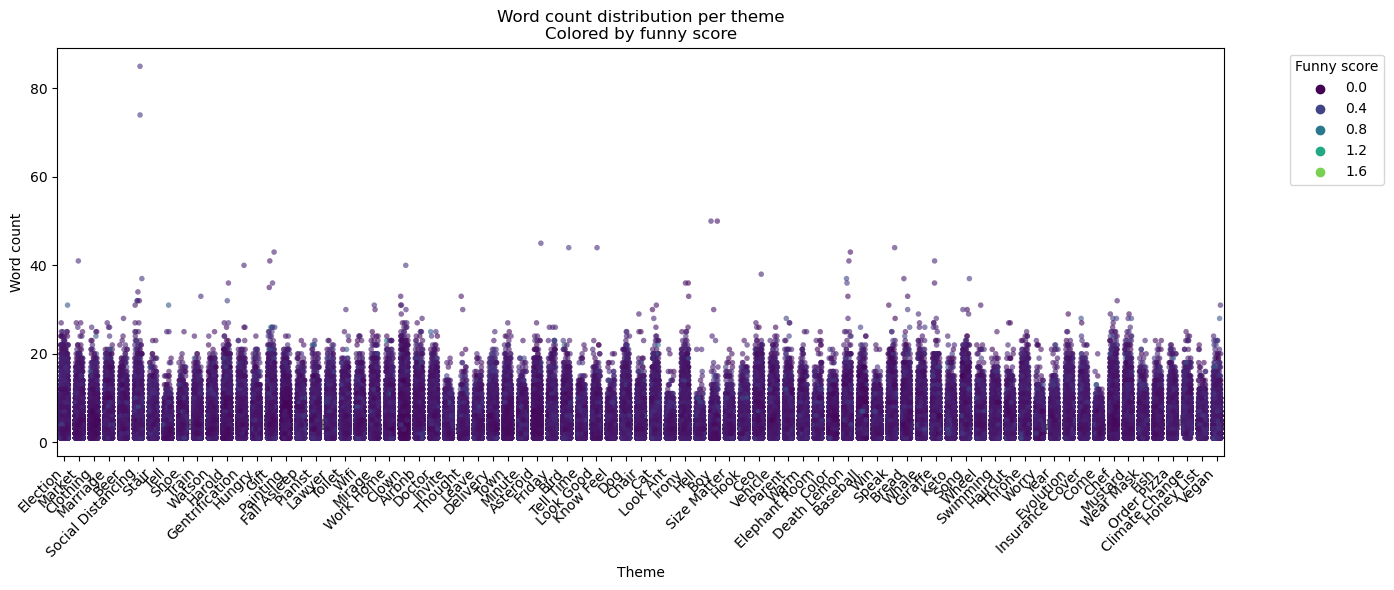

c:\Users\mered\anaconda3\Lib\site-packages\statsmodels\nonparametric\smoothers_lowess.py:227: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),
C:\Users\mered\AppData\Local\Temp\ipykernel_2752\640422376.py:97: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


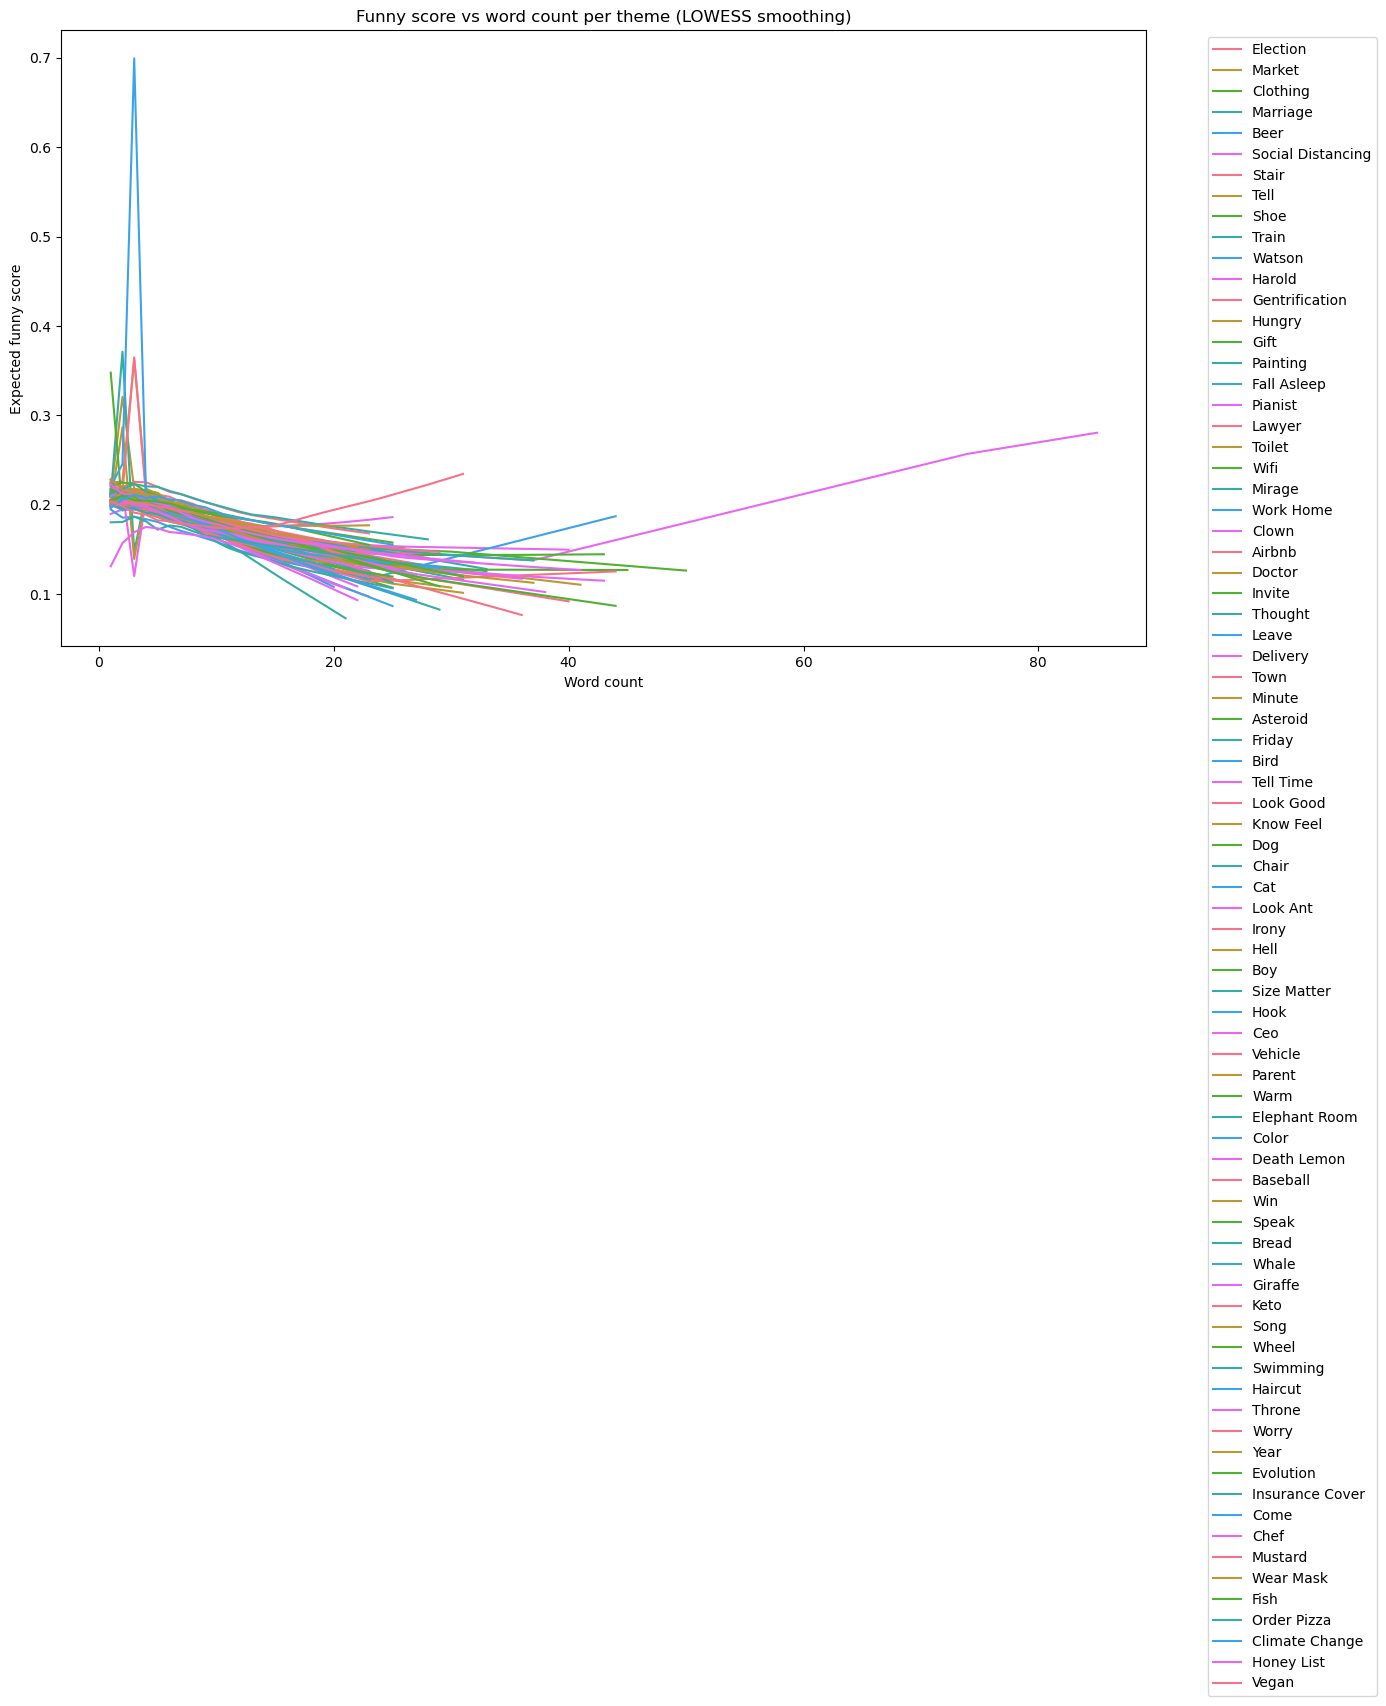

In [19]:
# make sure word counts exist
df['word_counts'] = df['clean_text'].str.split().str.len()
# filter extremes (important per theme )
df_theme = df[
    (df['word_counts'] <= 100) &
    (df['votes'] >= 5)   # avoid noisy captions
].copy()

# theme-wise correlation 
from scipy.stats import pearsonr

theme_corrs = []

for theme, g in df_theme.groupby('theme_label'):
    if len(g) >= 30:  # minimum data
        # scores
        g['total_votes'] = g['not_funny'] + g['somewhat_funny'] + g['funny'] # this is for each caption 

        # proportions for each category
        g['prop_not_funny'] = g['not_funny'] / g['total_votes']
        g['prop_somewhat_funny'] = g['somewhat_funny'] / g['total_votes']
        g['prop_funny'] = g['funny'] / g['total_votes']

        # weighted average (2 for funny, 1 for somewhat_funny, 0 for not_funny)
        g['funny_score_weighted'] = (g['funny'] * 2 + g['somewhat_funny'] * 1 + g['not_funny'] * 0) / g['total_votes']
        g['success_metric'] = g['funny_score_weighted']
        r, p = pearsonr(g['word_counts'], g['success_metric'])
        theme_corrs.append({
            'theme': theme,
            'r_word_funny': r,
            'p_value': p,
            'n': len(g)
        })

theme_corr_df = pd.DataFrame(theme_corrs).sort_values('r_word_funny')
print(theme_corr_df)

# visualisation 
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df_theme,
    x='theme_label',
    y='word_counts',
    color='lightgray',
    showfliers=False
)

sns.stripplot(
    data=df_theme,
    x='theme_label',
    y='word_counts',
    hue='success_metric',
    palette='viridis',
    alpha=0.6,
    jitter=0.25,
    size=4
)

plt.xticks(rotation=45, ha='right')
plt.ylabel("Word count")
plt.xlabel("Theme")
plt.title("Word count distribution per theme\nColored by funny score")

plt.legend(title="Funny score", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# visualisation 2 ( recommended word count per theme)
import statsmodels.api as sm

themes = df_theme['theme_label'].unique()

plt.figure(figsize=(14, 8))

for theme in themes:
    g = df_theme[df_theme['theme_label'] == theme]
    if len(g) < 40:
        continue

    lowess = sm.nonparametric.lowess(
        g['success_metric'],
        g['word_counts'],
        frac=0.3
    )

    plt.plot(
        lowess[:, 0],
        lowess[:, 1],
        label=theme
    )

plt.xlabel("Word count")
plt.ylabel("Expected funny score")
plt.title("Funny score vs word count per theme (LOWESS smoothing)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()




        => interpretation:

r_word_funny: Pearson correlation between word count and funny score for that theme.

Negative value (like -0.108 for "Ceo") → Longer captions tend to be slightly less funny in that theme.

Positive value (like 0.023 for "Honey List") → Longer captions tend to be slightly more funny.

The closer r is to 0, the weaker the linear relationship.

p_value: Tests if correlation is significantly different from 0.

Extremely small p-values (like 2.9e-99) → correlation is statistically significant, but keep in mind with huge sample sizes (n > 10,000), even tiny correlations can be “significant.”

n: Number of captions in that theme used for the calculation.

Key takeaway:
Most correlations are very small (between -0.1 and +0.02). That means word count has only a minor effect on funny score, even if statistically significant. You’re seeing patterns, but they are weak in practical terms.

In [21]:
import numpy as np
import plotly.graph_objects as go
from scipy.ndimage import gaussian_filter1d

fig = go.Figure()

for theme, sub in df.groupby("theme_label"):
    agg = (
        sub.groupby("word_counts")["funny"]
           .mean()
           .reset_index()
           .sort_values("word_counts")
    )

    # Skip sparse themes
    if len(agg) < 8:
        continue

    y_smooth = gaussian_filter1d(agg["funny"], sigma=2)

    fig.add_trace(
        go.Scatter(
            x=agg["word_counts"],
            y=y_smooth,
            mode="lines",
            name=theme,
            hovertemplate=(
                "Theme: " + theme +
                "<br>Words: %{x}" +
                "<br>Expected funniness: %{y:.2f}"
                "<extra></extra>"
            )
        )
    )

fig.update_layout(
    title="Effect of word count on funniness (smoothed curves)",
    xaxis_title="Number of words",
    yaxis_title="Expected funniness",
    template="plotly_white",
    hovermode="x unified"
)

fig.show()


#### 4.2.3 Do some words or does some kind of vocabulary richness correlate with higher scores (in general)?

Analysis of vocabulary richness using TTR (type-token ratio) where: 
- the mathematical computation is given by (#unique_words) / (total_words)
- it ranges from 0 (= no words or all words are identical) to 1 (=every word is unique)

In [22]:
# calculation of vocabulary richness metrics

# check if we already have these columns & remove them if they exist (in case of problems)
columns_to_remove = ['ttr', 'unique_words', 'total_words']
existing_cols = [col for col in columns_to_remove if col in df.columns]
if existing_cols:
    df = df.drop(columns=existing_cols)
    print(f"Removed existing columns: {existing_cols}")

# calculate vocab richness for all captions
vocab_metrics = ut.calculate_vocabulary_richness(df['text'], remove_stopwords=True)

# new columns to the main DataFrame
df = pd.concat([df, vocab_metrics], axis=1)

# some stats
print(f"average TTR: {df['ttr'].mean():.3f}")
print(f"average unique words per caption: {df['unique_words'].mean():.1f}")
print(f"average total words per caption: {df['total_words'].mean():.1f}")
print(f"dataset size: {len(df)} captions")


average TTR: 0.989
average unique words per caption: 4.9
average total words per caption: 5.0
dataset size: 2263328 captions


In [23]:
top_captions = df[df['success_metric'] >= top_cutoff].dropna(subset=['ttr', 'unique_words', 'total_words'])
bottom_captions = df[df['success_metric'] <= bottom_cutoff].dropna(subset=['ttr', 'unique_words', 'total_words'])

print(f"\nvocab richness comparison")
print("top performers:")
print(f"  TTR: {top_captions['ttr'].mean():.3f} ± {top_captions['ttr'].std():.3f}")
print(f"  Unique words: {top_captions['unique_words'].mean():.1f} ± {top_captions['unique_words'].std():.1f}")
print(f"  Total words: {top_captions['total_words'].mean():.1f} ± {top_captions['total_words'].std():.1f}")

print("\nbottom:")
print(f"  TTR: {bottom_captions['ttr'].mean():.3f} ± {bottom_captions['ttr'].std():.3f}")
print(f"  Unique words: {bottom_captions['unique_words'].mean():.1f} ± {bottom_captions['unique_words'].std():.1f}")
print(f"  Total words: {bottom_captions['total_words'].mean():.1f} ± {bottom_captions['total_words'].std():.1f}")


vocab richness comparison
top performers:
  TTR: 0.990 ± 0.060
  Unique words: 4.7 ± 2.3
  Total words: 4.8 ± 2.3

bottom:
  TTR: 0.988 ± 0.066
  Unique words: 5.0 ± 2.6
  Total words: 5.1 ± 2.7


<!-- The above code cell outputs the following:
```bash
    average TTR: 0.989
    average unique words per caption: 4.9
    average total words per caption: 5.0
    dataset size: 2292678 captions
``` -->


T-TESTS)
TTR (p-value) = 0.0000 ***
Unique words (p-value) = 0.0000 ***
Total words (p-value) = 0.0000 ***

correlation w/ success metric
TTR correlation: 0.012 (p-value: 0.0000)
unique words correlation: -0.047 (p-value: 0.0000)
total words correlation: -0.048 (p-value: 0.0000)


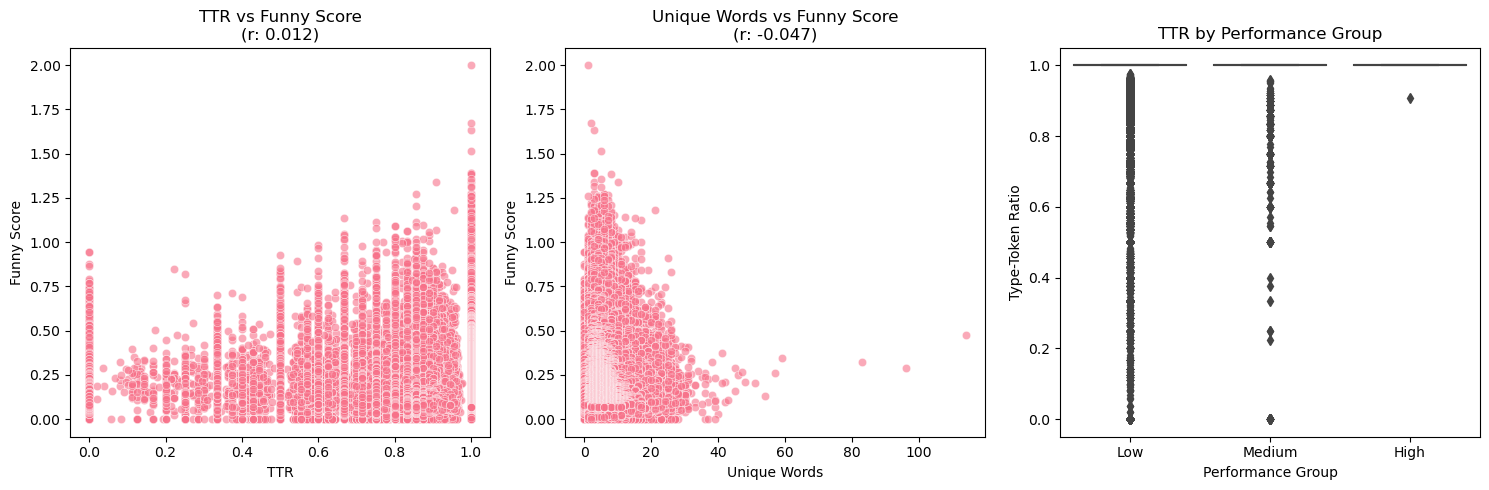

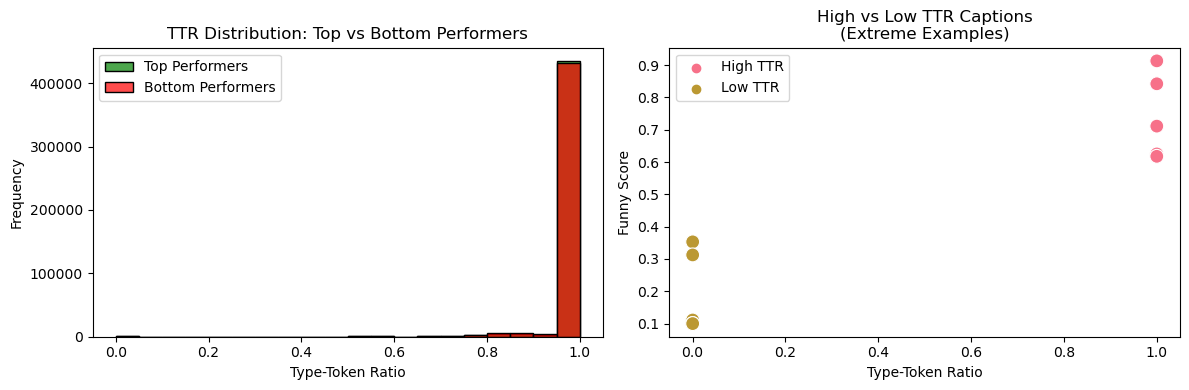

In [24]:
# Ensure no NaNs for t-test
top_ttr = top_captions['ttr'].dropna()
bottom_ttr = bottom_captions['ttr'].dropna()
top_unique = top_captions['unique_words'].dropna()
bottom_unique = bottom_captions['unique_words'].dropna()
top_total = top_captions['total_words'].dropna()
bottom_total = bottom_captions['total_words'].dropna()

# t-tests
t_stat_ttr, p_val_ttr = ttest_ind(top_ttr, bottom_ttr)
t_stat_unique, p_val_unique = ttest_ind(top_unique, bottom_unique)
t_stat_total, p_val_total = ttest_ind(top_total, bottom_total)

print(f"\nT-TESTS)")
print(f"TTR (p-value) = {p_val_ttr:.4f} {'***' if p_val_ttr < 0.001 else '**' if p_val_ttr < 0.01 else '*' if p_val_ttr < 0.05 else 'ns'}")
print(f"Unique words (p-value) = {p_val_unique:.4f} {'***' if p_val_unique < 0.001 else '**' if p_val_unique < 0.01 else '*' if p_val_unique < 0.05 else 'ns'}")
print(f"Total words (p-value) = {p_val_total:.4f} {'***' if p_val_total < 0.001 else '**' if p_val_total < 0.01 else '*' if p_val_total < 0.05 else 'ns'}")

# --- CORRELATIONS ---
# Drop rows with NaN or inf for correlation
df_corr = df[['ttr', 'unique_words', 'total_words', 'success_metric']].replace([np.inf, -np.inf], np.nan).dropna()

corr_ttr, p_corr_ttr = pearsonr(df_corr['ttr'], df_corr['success_metric'])
corr_unique, p_corr_unique = pearsonr(df_corr['unique_words'], df_corr['success_metric'])
corr_total, p_corr_total = pearsonr(df_corr['total_words'], df_corr['success_metric'])

print(f"\ncorrelation w/ success metric")
print(f"TTR correlation: {corr_ttr:.3f} (p-value: {p_corr_ttr:.4f})")
print(f"unique words correlation: {corr_unique:.3f} (p-value: {p_corr_unique:.4f})")
print(f"total words correlation: {corr_total:.3f} (p-value: {p_corr_total:.4f})")

# plot
ut.plot_linguistic_metrics(df, top_captions, bottom_captions, corr_ttr, corr_unique)



        => Interpretation: 
These results show that TTR, unique word count, and total word count differ reliably between your performance groups, but each has an extremely small relationship with the success (funny) score itself, likely because your sample size is huge. In other words, the effects are statistically significant but not practically important.
​

T‑tests: what they tell you
Very small p‑values (reported as 0.0000 ***) for TTR, unique words, and total words mean the group means are not all equal; the observed differences are very unlikely under the null of “no difference,” given your large N.
​

However, t‑tests do not tell you how large those differences are; for that you would need an effect size such as Cohen’s d, which could still be tiny even with p≈0 because p shrinks as sample size grows.
​

Correlations with success metric
Correlations of 0.012 (TTR), −0.047 (unique words), and −0.048 (total words) are conventionally considered negligible; they explain less than 0.3% of the variance in the funny score, which is effectively no predictive power.
​

The very small p‑values on these correlations again reflect statistical, not practical, significance: with very large datasets, even minuscule correlations become “significant” while still being useless for prediction or interpretation.
​

Putting it together for your study
Your plots match this story: the scatterplots are almost clouds with no visible trend, and the group distributions of TTR overlap heavily, even though the tests are significant.
​
​

The combined interpretation is that lexical diversity and length (TTR, unique words, total words) are not meaningful drivers of success; any real effect they have is so small that other factors must be doing almost all of the work.


## 5. Semantic Analysis / Is there a type of joke or humor which is funnier ?


### 5.1. Classifying the quotes 
In order to make the task easier, we classified each caption to one of the Berger’s humor categories ;

| Categories of Humour | What they mean |
|-----------|-----------|
|Language|Verbal humor, Allusion, Irony, Puns, Repartee, Wit, Ridicule|
|Logic|Ideational humor, Absurdity, Coincidence, Conceptual surprise, Outwitting, Caught out, Misunderstanding|
|Identity|Existential humor, Parody, Rigidity, Malicious pleasure, Condescension, Deceitful behavior, Self-deprecation|
|Action|Physical/ non-verbal humour, Peculiar face, Peculiar music, Clumsiness, Repulsive behavior|

With the help of Ollama and gpt-oss:120b (model of LLM), the top and worst 25 caption of each contest was classified. The restriction comes from the time it takes to run each classification ≈ 2s, and if you multiply this by ≈5000 caption per ≈380 contest, it would take around 49 days to run, plus there is a hourly and weekly limit using ollama's cloud...
Then the LLM classified each caption to all of the categories with a percentage (SEE CODE HERE classify_captions()), since one caption could be mixing 2 or more types of humor, and were cleaned (because the LLM do not always respect the format). The finals results look like this :   


In [3]:
pd.read_csv(str(CLASS_DIR)+'/612_cleaned.csv').head(10)

,caption_id,Language,Logic,Identity,Action
0,0,0.70,0.30,0.00,0.00
1,1,0.20,0.70,0.10,0.00
2,2,0.10,0.85,0.00,0.05
3,3,0.35,0.40,0.20,0.05
4,4,0.70,0.20,0.05,0.05
5,5,0.10,0.80,0.05,0.05
6,6,0.20,0.70,0.00,0.10
7,7,0.60,0.30,0.05,0.05
8,8,0.35,0.55,0.05,0.05
9,9,0.10,0.75,0.10,0.05


### 5.2 Analysing the results

#### 5.2.1 Visualisation and descritpive statistics

Once all the captions were classified, some observables were added : mean of the caption, the contest id, the dominant category as well as the dominant value. All the data was then saved to a new csv; super.csv. The analysis of super csv was then done.

In [7]:
df=pd.read_csv(str(CLASS_DIR)+'/super.csv')

cols = ['Logic', 'Identity', 'Action', 'Language', 'mean']

fig_pair = viz.plot_df_pairgrid_plotly(df,cols=cols,title='Pairwise relationships')
fig_hist = viz.plot_histograms(df,cols=cols,title='Marginal distributions')
fig_comp= viz.plot_dominant_vs_mean(df,title='Dominant Cat vs Mean')

fig_pair.show()
fig_hist.show()
fig_comp.show()

stats = df[['Logic','Identity','Action','Language','mean']].describe()
print('================================ Descriptive statistics ========================')
print(stats)

viz.descriptive_analysis(df)



================================ Descriptive statistics ========================
              Logic      Identity        Action      Language          mean
count  19145.000000  19145.000000  19145.000000  19145.000000  19145.000000
mean       0.379003      0.074297      0.049961      0.496601      1.392375
std        0.239183      0.119001      0.056497      0.253854      0.378952
min        0.000000      0.000000      0.000000      0.000000      0.857143
25%        0.200000      0.020000      0.020000      0.200000      1.021277
50%        0.300000      0.050000      0.050000      0.550000      1.166667
75%        0.600000      0.050000      0.050000      0.700000      1.747036
max        0.950000      0.920000      0.900000      0.950000      2.998918
Statistics by dominant category:
  dominant_category      mean       std       sem  count  ci_lower  ci_upper
0            Action  1.384522  0.372501  0.037438     99  1.311144  1.457900
1          Identity  1.405824  0.375979  0.01407

,dominant_category,mean,std,sem,count,ci_lower,ci_upper
0,Action,1.384522,0.372501,0.037438,99,1.311144,1.457900
1,Identity,1.405824,0.375979,0.014071,714,1.378245,1.433402
2,Language,1.388062,0.379287,0.003518,11623,1.381167,1.394958
3,Logic,1.398532,0.378746,0.004624,6709,1.389469,1.407595


From the first graph, the scatters plots from the different categories make sense following 1-x line because for low category1 percetages you can have high values of other categores, and as the categorie values augments, the others diminish. Another suprising result is that there are some caption that are classified to Action which is not possible since it is non-verbal humor showing that the task did not perform very well... Furthermore it seems that there are no relationships between the caption humor categories and the caption mean. The litlle space between the both groups accouring at mean=1.2 to mean=1.5 is explained by our subsampling of the first and last 25 captions. <br>
<br>
The histograms of the categories and mean show that logic and language are the most higly common types of humor, eventhough every type of humor is present showed by the high peaks of each distribution at the begining. The mean distribution surely follows an exponential (VERIFIER AVEC LES GRAPH AU DEBUT) distribution, but the hole between mean=1.15 to mean=1.45 is explained by the subsampling again.<br>
<br>
Finnaly the last scatter plot with the dominat categories vs the mean do not show any specific relationship. The separation of the 2 groups is again explained by the subsampling.<br>
<br>
The first descriptive statistics shows that, again, logic and language are the higly common types of humor, with their respective means of 0.38 and 0.50, and Identity humor and Action are not very present humour since their 75% quantiles are 0.05. Eventhough, their max values suggest that there are some caption highly related to those categories (eventhough Action is not accurate). <br>
<br>
The scond statistics shows that there is realy no effects from the categories to the means since they are very very close in the means. The bar plots show the same thing.


#### 5.2.2 A bit more advance statistics

The first results suggest strongly that there is no effect but in order to be sure, some more statistics were done

In [11]:
viz.heatmap(df,['Logic', 'Identity', 'Action', 'Language', 'mean'])

mod= smf.ols(formula='mean~ Logic + Identity + Action + Language',data=df)
res = mod.fit()
print(res.summary())

Correlation Matrix:
             Logic  Identity    Action  Language      mean
Logic     1.000000 -0.206873  0.069519 -0.860492  0.018524
Identity -0.206873  1.000000 -0.015515 -0.270310 -0.002733
Action    0.069519 -0.015515  1.000000 -0.280336 -0.016356
Language -0.860492 -0.270310 -0.280336  1.000000 -0.012405
mean      0.018524 -0.002733 -0.016356 -0.012405  1.000000


                            OLS Regression Results                            
Dep. Variable:                   mean   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     3.321
Date:                Fri, 19 Dec 2025   Prob (F-statistic):            0.00999
Time:                        21:47:43   Log-Likelihood:                -8581.2
No. Observations:               19145   AIC:                         1.717e+04
Df Residuals:                   19140   BIC:                         1.721e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.9729      0.495      1.965      0.0

The corrolation matrixn now reaaly shows that there are no corrolations between the humor categories and the caption means. However, it is interesting to notice the high negative correlation between Language and Logic. From the definitions, both categories seemed a bit related, but at least the classifier, not very reliable, did not consider them together.

The regression now really indicates that there are no effect of the humor category with the mean, with an explained variance of 0.001, and non-significant coeeficients.

## 6. Timing and Context Analysis



### 6.1 Context Analysis

As explained in our README, we have eventually decided to drop our Contextual Analysis after exploring a reduced snipet of the GDELT database. Here, you can have insight into what it looks like :  

---
```python
    #dataset_path = file_path = pd.read_txt(r"C:\Users\hanna\ADA\2025\newyorker_caption_contest\data\510.csv")
    dataset_path = r"C:\Users\hanna\ADA\2025\additional_dataset\GDELT.MASTERREDUCEDV2.txt"
    from itertools import islice

    with open(dataset_path, "r") as f:
        for line in f.readlines()[:5]:
            print(line.strip())
```
---
The code above outputs the following:

```bash
    Date	Source	Target	CAMEOCode	NumEvents	NumArts	QuadClass	Goldstein	SourceGeoType	SourceGeoLat	SourceGeoLong	TargetGeoType	TargetGeoLat	TargetGeoLong	ActionGeoType	ActionGeoLat	ActionGeoLong
    19790101	AFR	FRA	043	1	4	1	2.8
    19790101	AFR	FRA	050	2	9	1	3.5
    19790101	AFR	FRAGOV	043	2	19	1	2.8	1	46	2	1	46	2	1	46	2
    19790101	AFR	ZMB	100	2	18	3	-5
```

As you can see, the data goes back to January 1rst 1979 and is quite a swiss cheese. More specifically, we are missing quite a lot of data in each line. Each one of them represent a new entry updated each 15mins automatically by GDELT.

Finally, this specific file took a really long time to download as it is 6GB (even if it is a reduced version) and really hard to be found on the GDELT website.

We also tried downloading the time window of interest for our dataset which is from 2016 to 2024. You can download it yourself by using the python script [GDELT_dataloader.py](utils/GDELT_dataloader.py) for a specified datetime range. We realised while downloading that for a 30 days period, we already had 3GB or so of raw data. For the whole dataset from 2016 to 2024 this would give us an **enormous augmented dataset of 288GB!**

This dataset is simply way to large to deal with on our personal computer and also the data wrangling involved to clean it is in itself a whole project. This outcome further encouraged us to drop the idea of performing contextual analysis, since the rest of our findings encourages us to follow other analysis ideas. 

### Timing Analysis
We have added dates conresponding to each contest using a function "add_contest_dates". 
For reference : 

In [ ]:
contest_no_dates = pd.read_json(JSON_DIR)
contest_no_dates.head()

NameError: name 'JSON_DIR' is not defined

We then added the relevant dates like this : 

In [ ]:
contest_with_dates = add_contest_dates(contest_no_dates)
contest_with_dates.head()

Then proceeded to plot the dates on the X-axis, Y1-axis corresponds the number of submitted captions and Y2-axis corresponds to mean funniness overtime.


In [ ]:
plot_captions_and_funniness_timeline_plotly(CSV_CLEAN_DIR, contest_with_dates, sigma=4)

This function generates an interactive timeline visualization showing how contest popularity and average funniness evolve over time. For each contest between 510 and 895, it loads the corresponding cleaned CSV file (when available) and computes two summary metrics: the number of submitted captions and the mean funniness score across captions.

These contest-level metrics are then merged with publication dates, allowing the data to be ordered chronologically. This enables a direct comparison of how engagement and perceived humor change over the lifespan of the dataset.

To improve readability, both time series are smoothed using a Gaussian filter (`gaussian_filter1d`) with standard deviation σ (which we have set at 4). This Gaussian smoothing acts as a low-pass filter, reducing short-term noise while preserving long-term trends. The smoothed curves are included solely as visual guides to support interpretation and are not used to assess correlation or draw statistical conclusions.

The visualization is built using Plotly with two overlaid y-axes: the left axis represents the number of captions, while the right axis shows the mean funniness score. Raw values are displayed as semi-transparent markers, and the smoothed trends are overlaid as continuous lines. Interactive hover tooltips and a unified hover mode facilitate comparison between the two metrics over time.

Finally, the figure is saved as an HTML file for integration into the website and displayed directly in the notebook. The merged dataset used for the plot is returned to allow further analysis if needed.

The goal of this analysis is not to enforce correlation, but to provide visual support and open up a conversation about comedic timing.


## 7. Conclusion

To conclude, up until now, we were not only able to dive into the provided NewYorker’s dataset, but we also managed to perform : 

Filtering and transformation of the data through data wrangling. This confirmed that we are on a good track in handling the data in its size, and also that we were able to verify that we understood the data’s format (CSV, JSON, png…). Through different methods to fill in missing data, as well as plots and graphs, we were able to visualize the main features of the dataset. We still need to finish our functions that correct the entire dataset.
We also considered ways to enrich the data, through an additional dataset, but also using calculations and generative AI for image descriptions.
Furthermore, we are confident that our proposed plan is not only feasible, but highly likely to give us an engaging and gripping datastory. When it comes to the methods we have found, these will be further dived into in the following weeks, as exposed in our proposed timeline. We have proposed statstical means which will be used to answer to dig deeper into our research questions.

Ultimately, we are looking forward to not only dive deeper, but also construct a robust story around the question : What makes a joke funny ?